# MedFusionNet — Clean Camera-Ready Execution Notebook

This notebook replaces the exploratory `waveforms.ipynb` / `final-mimic.ipynb` workflow with one reproducible pipeline.

**Primary validated task:** ICU-admission classification using structured triage data, waveform-summary features, and Bio_ClinicalBERT chief-complaint embeddings.

**Secondary task:** ED length-of-stay (LOS) regression using complete first-60-minute vital-sign sequences with GRU / GRU-D. Unlike the earlier exploratory notebook, this version does **not** truncate training to 100 visits and never replaces NaN predictions with zero.

The notebook:
- uses the predefined MC-MED random train/validation/test split;
- aligns every modality by `CSN`;
- fits preprocessing on training data only;
- reports ablations and bootstrap 95% confidence intervals;
- caches Bio_ClinicalBERT embeddings;
- saves final tables to CSV for the camera-ready manuscript.


In [14]:
# Optional on a fresh Kaggle runtime:
# !pip install -q transformers xgboost

import os, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA = Path("/kaggle/input/health-care-mimic")
OUT = Path("/kaggle/working/medfusionnet_clean")
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Data:", DATA)
print("Output:", OUT)


Device: cuda
Data: /kaggle/input/health-care-mimic
Output: /kaggle/working/medfusionnet_clean


## 1. Load and validate MC-MED files

In [16]:
from pathlib import Path
import pandas as pd

# ============================================================
# DATA PATH
# ============================================================

DATA = Path(
    "/kaggle/input/datasets/abinayavinoth/health-care-mimic"
)

print("=" * 70)
print("MedFusionNet - MC-MED Data Loading")
print("=" * 70)

print("\nDataset path:")
print(DATA)

print("\nDataset path exists:", DATA.exists())

if not DATA.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA}"
    )


# ============================================================
# REQUIRED FILES
# ============================================================

required = [
    "visits.csv",
    "numerics.csv",
    "waveform_summary.csv",
    "split_random_train.csv",
    "split_random_val.csv",
    "split_random_test.csv"
]

missing = [
    filename
    for filename in required
    if not (DATA / filename).exists()
]

if missing:

    print("\nAvailable files:")

    for file in sorted(DATA.iterdir()):
        print(" -", file.name)

    raise FileNotFoundError(
        f"Missing required files: {missing}"
    )

print("\n✓ All required files found.")


# ============================================================
# LOAD MAIN DATA FILES
# ============================================================

print("\nLoading visits.csv...")

visits = pd.read_csv(
    DATA / "visits.csv",
    low_memory=False
)


print("Loading numerics.csv...")

numerics = pd.read_csv(
    DATA / "numerics.csv",
    low_memory=False
)


print("Loading waveform_summary.csv...")

waveforms = pd.read_csv(
    DATA / "waveform_summary.csv",
    low_memory=False
)


# ============================================================
# LOAD SPLIT FILES
#
# IMPORTANT:
# These files do NOT contain a header.
#
# Without header=None pandas interprets the first CSN
# (for example 98874959) as the column name.
# ============================================================

print("Loading split_random_train.csv...")

split_train = pd.read_csv(
    DATA / "split_random_train.csv",
    header=None,
    names=["CSN"]
)


print("Loading split_random_val.csv...")

split_val = pd.read_csv(
    DATA / "split_random_val.csv",
    header=None,
    names=["CSN"]
)


print("Loading split_random_test.csv...")

split_test = pd.read_csv(
    DATA / "split_random_test.csv",
    header=None,
    names=["CSN"]
)


# ============================================================
# CLEAN COLUMN NAMES
# ============================================================

visits.columns = visits.columns.str.strip()
numerics.columns = numerics.columns.str.strip()
waveforms.columns = waveforms.columns.str.strip()

split_train.columns = split_train.columns.str.strip()
split_val.columns = split_val.columns.str.strip()
split_test.columns = split_test.columns.str.strip()


# ============================================================
# NORMALIZE CSN DATA TYPE
#
# Using string avoids problems if one file stores CSN as int
# and another stores it as object/string.
# ============================================================

for dataframe in [
    visits,
    numerics,
    waveforms,
    split_train,
    split_val,
    split_test
]:

    if "CSN" not in dataframe.columns:

        raise ValueError(
            f"""
CSN column missing.

Available columns:

{dataframe.columns.tolist()}
"""
        )

    dataframe["CSN"] = (
        dataframe["CSN"]
        .astype(str)
        .str.strip()
        .str.replace(".0", "", regex=False)
    )


print("\n✓ CSN column validated.")


# ============================================================
# REMOVE EMPTY / INVALID CSN VALUES
# ============================================================

for dataframe in [
    visits,
    numerics,
    waveforms,
    split_train,
    split_val,
    split_test
]:

    dataframe.dropna(
        subset=["CSN"],
        inplace=True
    )

    dataframe.drop(
        dataframe[
            dataframe["CSN"].isin(
                ["", "nan", "None"]
            )
        ].index,
        inplace=True
    )


# ============================================================
# REMOVE DUPLICATES FROM SPLIT FILES
# ============================================================

split_train = (
    split_train
    .drop_duplicates(subset=["CSN"])
    .reset_index(drop=True)
)

split_val = (
    split_val
    .drop_duplicates(subset=["CSN"])
    .reset_index(drop=True)
)

split_test = (
    split_test
    .drop_duplicates(subset=["CSN"])
    .reset_index(drop=True)
)


# ============================================================
# DATASET SHAPES
# ============================================================

print("\n" + "=" * 70)
print("DATASET SHAPES")
print("=" * 70)

print(
    f"visits:      "
    f"{visits.shape[0]:,} rows × "
    f"{visits.shape[1]} columns"
)

print(
    f"numerics:    "
    f"{numerics.shape[0]:,} rows × "
    f"{numerics.shape[1]} columns"
)

print(
    f"waveforms:   "
    f"{waveforms.shape[0]:,} rows × "
    f"{waveforms.shape[1]} columns"
)

print(
    f"train split: {len(split_train):,}"
)

print(
    f"val split:   {len(split_val):,}"
)

print(
    f"test split:  {len(split_test):,}"
)


# ============================================================
# CHECK FIRST FEW SPLIT VALUES
# ============================================================

print("\n" + "=" * 70)
print("SPLIT FILE CHECK")
print("=" * 70)

print("\nTrain:")
display(split_train.head())

print("\nValidation:")
display(split_val.head())

print("\nTest:")
display(split_test.head())


# ============================================================
# UNIQUE CSN COUNTS
# ============================================================

print("\n" + "=" * 70)
print("UNIQUE CSN COUNTS")
print("=" * 70)

print(
    "Visits:",
    f"{visits['CSN'].nunique():,}"
)

print(
    "Numerics:",
    f"{numerics['CSN'].nunique():,}"
)

print(
    "Waveforms:",
    f"{waveforms['CSN'].nunique():,}"
)

print(
    "Train:",
    f"{split_train['CSN'].nunique():,}"
)

print(
    "Validation:",
    f"{split_val['CSN'].nunique():,}"
)

print(
    "Test:",
    f"{split_test['CSN'].nunique():,}"
)


# ============================================================
# SPLIT LEAKAGE CHECK
# ============================================================

train_ids = set(
    split_train["CSN"]
)

val_ids = set(
    split_val["CSN"]
)

test_ids = set(
    split_test["CSN"]
)


train_val_overlap = (
    train_ids & val_ids
)

train_test_overlap = (
    train_ids & test_ids
)

val_test_overlap = (
    val_ids & test_ids
)


print("\n" + "=" * 70)
print("SPLIT LEAKAGE CHECK")
print("=" * 70)

print(
    "Train / Validation overlap:",
    len(train_val_overlap)
)

print(
    "Train / Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation / Test overlap:",
    len(val_test_overlap)
)


if (
    len(train_val_overlap) == 0
    and
    len(train_test_overlap) == 0
    and
    len(val_test_overlap) == 0
):

    print(
        "\n✓ No CSN leakage detected "
        "between train/validation/test."
    )

else:

    print(
        "\n⚠ WARNING: Split overlap detected!"
    )


# ============================================================
# CHECK HOW MANY SPLIT CSNs EXIST IN VISITS
# ============================================================

visit_ids = set(
    visits["CSN"]
)


train_found = len(
    train_ids & visit_ids
)

val_found = len(
    val_ids & visit_ids
)

test_found = len(
    test_ids & visit_ids
)


print("\n" + "=" * 70)
print("SPLIT → VISITS MATCH CHECK")
print("=" * 70)

print(
    f"Train found in visits: "
    f"{train_found:,} / "
    f"{len(train_ids):,}"
)

print(
    f"Validation found in visits: "
    f"{val_found:,} / "
    f"{len(val_ids):,}"
)

print(
    f"Test found in visits: "
    f"{test_found:,} / "
    f"{len(test_ids):,}"
)


# ============================================================
# DISPLAY ACTUAL COLUMN NAMES
# ============================================================

print("\n" + "=" * 70)
print("VISITS COLUMNS")
print("=" * 70)

for column in visits.columns:
    print(column)


print("\n" + "=" * 70)
print("NUMERICS COLUMNS")
print("=" * 70)

for column in numerics.columns:
    print(column)


print("\n" + "=" * 70)
print("WAVEFORM COLUMNS")
print("=" * 70)

for column in waveforms.columns:
    print(column)


# ============================================================
# IMPORTANT VISIT COLUMN CHECK
# ============================================================

important_visit_columns = [
    "CSN",
    "Admit_service",
    "Age",
    "Gender",
    "Means_of_arrival",
    "Triage_Temp",
    "Triage_HR",
    "Triage_RR",
    "Triage_SpO2",
    "Triage_SBP",
    "Triage_DBP"
]


print("\n" + "=" * 70)
print("IMPORTANT VISIT COLUMN CHECK")
print("=" * 70)


for column in important_visit_columns:

    if column in visits.columns:

        print(
            f"✓ {column}"
        )

    else:

        print(
            f"⚠ NOT FOUND: {column}"
        )


# ============================================================
# WAVEFORM COLUMN CHECK
# ============================================================

important_waveform_columns = [
    "CSN",
    "Segments",
    "Duration",
    "Type"
]


print("\n" + "=" * 70)
print("WAVEFORM COLUMN CHECK")
print("=" * 70)


for column in important_waveform_columns:

    if column in waveforms.columns:

        print(
            f"✓ {column}"
        )

    else:

        print(
            f"⚠ NOT FOUND: {column}"
        )


# ============================================================
# SAMPLE DATA
# ============================================================

print("\n" + "=" * 70)
print("VISITS SAMPLE")
print("=" * 70)

display(
    visits.head()
)


print("\n" + "=" * 70)
print("NUMERICS SAMPLE")
print("=" * 70)

display(
    numerics.head()
)


print("\n" + "=" * 70)
print("WAVEFORM SAMPLE")
print("=" * 70)

display(
    waveforms.head()
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("DATA LOADING SUCCESSFUL")
print("=" * 70)

print(
    "\n✓ Dataset loaded."
)

print(
    "✓ Headerless split files corrected."
)

print(
    "✓ CSN standardized."
)

print(
    "✓ Duplicate split CSNs removed."
)

print(
    "✓ Split leakage checked."
)

print(
    "✓ Split-to-visits matching checked."
)

print(
    "\nReady for MedFusionNet preprocessing."
)

MedFusionNet - MC-MED Data Loading

Dataset path:
/kaggle/input/datasets/abinayavinoth/health-care-mimic

Dataset path exists: True

✓ All required files found.

Loading visits.csv...
Loading numerics.csv...
Loading waveform_summary.csv...
Loading split_random_train.csv...
Loading split_random_val.csv...
Loading split_random_test.csv...

✓ CSN column validated.

DATASET SHAPES
visits:      118,385 rows × 33 columns
numerics:    47,821,508 rows × 5 columns
waveforms:   188,315 rows × 4 columns
train split: 94,657
val split:   12,062
test split:  11,666

SPLIT FILE CHECK

Train:


,CSN
0,98874959
1,99354408
2,99121037
3,99327434
4,99502864



Validation:


,CSN
0,99603825
1,99908562
2,99892292
3,99259539
4,99239771



Test:


...


NUMERICS SAMPLE


,CSN,Source,Measure,Value,Time
0,99314694,Chart,HR,81.0,2231-09-14T13:44:37Z
1,99314694,Chart,RR,18.0,2231-09-14T13:44:37Z
2,99314694,Chart,SpO2,98.0,2231-09-14T13:44:37Z
3,99314694,Chart,SBP,145.0,2231-09-14T13:44:37Z
4,99314694,Chart,DBP,87.0,2231-09-14T13:44:37Z



WAVEFORM SAMPLE


,CSN,Type,Segments,Duration
0,99633476,II,1,2204.742
1,99633476,Resp,1,2234.096
2,99633476,Pleth,1,1873.120
3,99872476,Pleth,1,97.296
4,99960476,II,4,12818.304



DATA LOADING SUCCESSFUL

✓ Dataset loaded.
✓ Headerless split files corrected.
✓ CSN standardized.
✓ Duplicate split CSNs removed.
✓ Split leakage checked.
✓ Split-to-visits matching checked.

Ready for MedFusionNet preprocessing.


DATASET SHAPE SUMMARY


,Dataset,Rows,Columns
0,Visits,118385,33
1,Numerics,47821508,5
2,Waveforms,188315,4
3,Train split,94657,1
4,Validation split,12062,1
5,Test split,11666,1


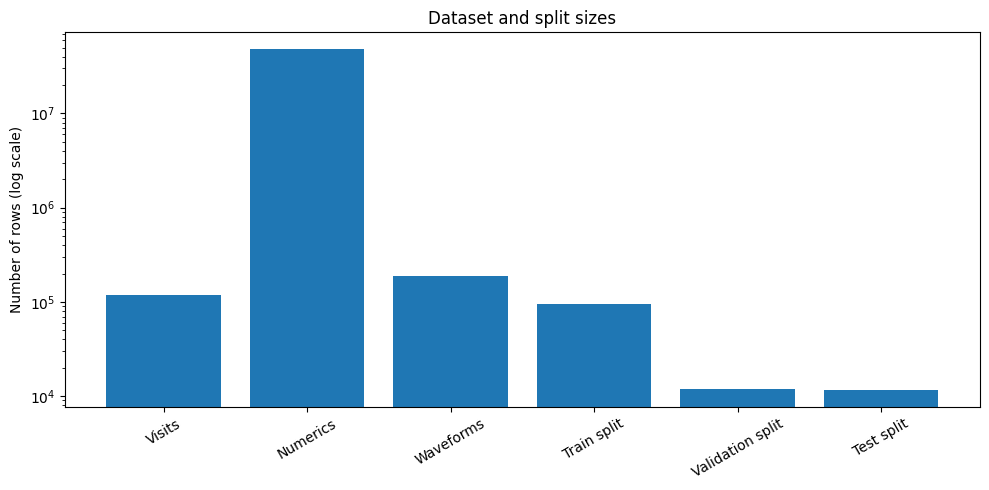

,Split,Encounters
0,Train,94657
1,Validation,12062
2,Test,11666


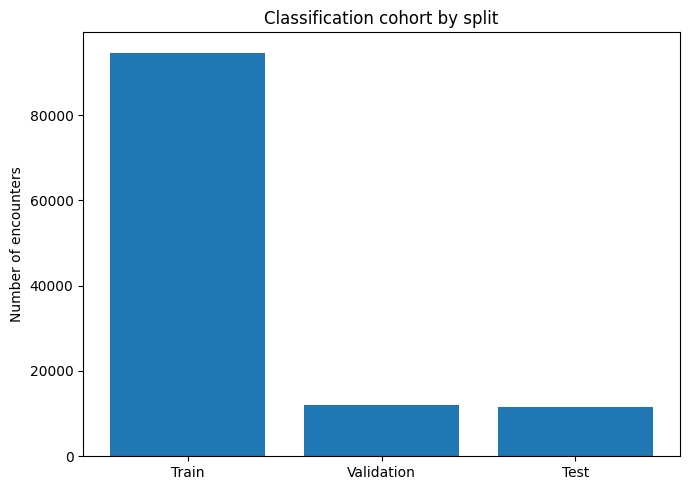

In [38]:
# ============================================================
# VISUALIZATION 1
# DATASET SHAPE + MODALITY COVERAGE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("DATASET SHAPE SUMMARY")
print("=" * 70)

shape_rows = []

for name, frame in [
    ("Visits", visits),
    ("Numerics", numerics),
    ("Waveforms", waveforms),
    ("Train split", split_train),
    ("Validation split", split_val),
    ("Test split", split_test),
]:

    shape_rows.append({
        "Dataset": name,
        "Rows": len(frame),
        "Columns": len(frame.columns)
    })

shape_df = pd.DataFrame(shape_rows)

display(shape_df)

# Plot rows on log scale because tables may differ greatly in size
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    shape_df["Dataset"],
    shape_df["Rows"]
)

ax.set_yscale("log")
ax.set_ylabel("Number of rows (log scale)")
ax.set_title("Dataset and split sizes")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# CLASSIFICATION SPLIT SIZE
# ============================================================

classification_sizes = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Encounters": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

display(classification_sizes)

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    classification_sizes["Split"],
    classification_sizes["Encounters"]
)

ax.set_ylabel("Number of encounters")
ax.set_title("Classification cohort by split")

plt.tight_layout()
plt.show()

## 2. ICU-admission classification

The label follows the original implementation: `Admit_service` containing **Critical Care** or **ICU**.

Waveform data are encounter-level summary features—not raw-signal artifact-rejection features.


In [17]:
if "Admit_service" not in visits.columns:
    raise KeyError("visits.csv must contain Admit_service for ICU_LABEL")

df = visits.copy()
df["ICU_LABEL"] = (
    df["Admit_service"].astype(str)
      .str.contains("Critical Care|ICU", case=False, na=False)
      .astype(int)
)

# Aggregate waveform_summary.csv exactly at encounter level
needed_wf = {"CSN", "Segments", "Duration", "Type"}
if not needed_wf.issubset(waveforms.columns):
    raise KeyError(f"waveform_summary.csv must contain {needed_wf}")

wf_agg = waveforms.groupby("CSN").agg(
    total_segments=("Segments", "sum"),
    total_duration=("Duration", "sum"),
    n_waveform_types=("Type", "nunique")
).reset_index()

wf_types = pd.pivot_table(
    waveforms, index="CSN", columns="Type", values="Segments",
    aggfunc="count", fill_value=0
).reset_index()

for c in wf_types.columns:
    if c != "CSN":
        wf_types[c] = (wf_types[c] > 0).astype(int)

wf_features = wf_agg.merge(wf_types, on="CSN", how="left")
df = df.merge(wf_features, on="CSN", how="left")

for c in wf_features.columns:
    if c != "CSN" and c in df.columns:
        df[c] = df[c].fillna(0)

STRUCT_COLS = [
    "Age", "Gender", "Means_of_arrival", "Triage_Temp",
    "Triage_HR", "Triage_RR", "Triage_SpO2",
    "Triage_SBP", "Triage_DBP"
]
missing_struct = [c for c in STRUCT_COLS if c not in df.columns]
if missing_struct:
    raise KeyError(f"Missing structured columns: {missing_struct}")

WAVE_COLS = ["total_segments", "total_duration", "n_waveform_types"]
for c in ["II", "Pleth", "Resp"]:
    if c in df.columns:
        WAVE_COLS.append(c)

train_ids = set(split_train["CSN"])
val_ids   = set(split_val["CSN"])
test_ids  = set(split_test["CSN"])

train_df = df[df.CSN.isin(train_ids)].copy()
val_df   = df[df.CSN.isin(val_ids)].copy()
test_df  = df[df.CSN.isin(test_ids)].copy()

print("Classification cohorts:", train_df.shape, val_df.shape, test_df.shape)
print("ICU prevalence:",
      train_df.ICU_LABEL.mean(), val_df.ICU_LABEL.mean(), test_df.ICU_LABEL.mean())
print("Waveform features:", WAVE_COLS)


Classification cohorts: (94657, 40) (12062, 40) (11666, 40)
ICU prevalence: 0.014314842008514954 0.014508373404078926 0.01320075432881879
Waveform features: ['total_segments', 'total_duration', 'n_waveform_types', 'II', 'Pleth', 'Resp']


### 2.1 Leakage-safe structured preprocessing + XGBoost

In [18]:
categorical = [c for c in ["Gender", "Means_of_arrival"] if c in STRUCT_COLS]
numeric = [c for c in STRUCT_COLS if c not in categorical]

def make_preprocessor(feature_cols):
    cats = [c for c in categorical if c in feature_cols]
    nums = [c for c in feature_cols if c not in cats]
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median"))
        ]), nums),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cats)
    ], remainder="drop")

XGB_PARAMS = dict(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEED
)

def fit_xgb(feature_cols):
    prep = make_preprocessor(feature_cols)
    Xtr = prep.fit_transform(train_df[feature_cols])
    Xva = prep.transform(val_df[feature_cols])
    Xte = prep.transform(test_df[feature_cols])

    model = XGBClassifier(**XGB_PARAMS)
    model.fit(Xtr, train_df.ICU_LABEL.values)
    return prep, model, Xva, Xte

prep_v, model_v, Xv_val, Xv_test = fit_xgb(STRUCT_COLS)
p_v_val  = model_v.predict_proba(Xv_val)[:,1]
p_v_test = model_v.predict_proba(Xv_test)[:,1]

SW_COLS = STRUCT_COLS + WAVE_COLS
prep_sw, model_sw, Xsw_val, Xsw_test = fit_xgb(SW_COLS)
p_sw_val  = model_sw.predict_proba(Xsw_val)[:,1]
p_sw_test = model_sw.predict_proba(Xsw_test)[:,1]

print("Vitals validation AUROC:", roc_auc_score(val_df.ICU_LABEL, p_v_val))
print("Vitals+wave validation AUROC:", roc_auc_score(val_df.ICU_LABEL, p_sw_val))


Vitals validation AUROC: 0.8648812027545099
Vitals+wave validation AUROC: 0.8964323570767585


### 2.2 Bio_ClinicalBERT chief-complaint embeddings

In [22]:
# ============================================================
# Bio_ClinicalBERT TEXT EMBEDDINGS
# ============================================================

import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


# ============================================================
# CONFIGURATION
# ============================================================

TEXT_MODEL = "emilyalsentzer/Bio_ClinicalBERT"

MAX_LEN = 64

BERT_BATCH = 64


# ============================================================
# FIND TEXT / CHIEF COMPLAINT COLUMN
#
# MC-MED commonly uses "CC" for Chief Complaint.
# Other possible names are included for robustness.
# ============================================================

TEXT_CANDIDATES = [
    "CC",
    "Chief_complaint",
    "Chief_Complaint",
    "chief_complaint",
    "ChiefComplaint",
    "chiefComplaint",
    "Chief Complaint",
    "Complaint",
    "complaint"
]


TEXT_COL = next(
    (
        column
        for column in TEXT_CANDIDATES
        if column in df.columns
    ),
    None
)


# ============================================================
# FALLBACK SEARCH
# ============================================================

if TEXT_COL is None:

    print("Exact chief-complaint column not found.")
    print("\nSearching for possible text columns...")

    possible_text_columns = []

    for column in df.columns:

        name = column.lower()

        if (
            "complaint" in name
            or name == "cc"
            or "chief" in name
            or "reason" in name
            or "note" in name
            or "text" in name
        ):

            possible_text_columns.append(column)

    print(
        "\nPossible text columns:",
        possible_text_columns
    )

    if len(possible_text_columns) == 1:

        TEXT_COL = possible_text_columns[0]

        print(
            f"\nAutomatically selected: {TEXT_COL}"
        )

    elif len(possible_text_columns) > 1:

        print(
            "\nMultiple possible text columns found."
        )

        print(
            "Using the first candidate:",
            possible_text_columns[0]
        )

        TEXT_COL = possible_text_columns[0]

    else:

        raise KeyError(
            "\nNo suitable chief-complaint/text column "
            "could be found.\n\n"
            f"Available columns are:\n{df.columns.tolist()}"
        )


# ============================================================
# CONFIRM SELECTED COLUMN
# ============================================================

print("\n" + "=" * 70)
print("TEXT COLUMN")
print("=" * 70)

print(
    f"Selected text column: {TEXT_COL}"
)


# ============================================================
# INSPECT TEXT
# ============================================================

print("\nSample text:")

display(
    df[
        ["CSN", TEXT_COL]
    ].head(10)
)


# ============================================================
# TEXT AVAILABILITY
# ============================================================

text_available = (
    df[TEXT_COL]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)


print(
    "\nTotal encounters:",
    f"{len(df):,}"
)

print(
    "Encounters with text:",
    f"{text_available.sum():,}"
)

print(
    "Missing/empty text:",
    f"{(~text_available).sum():,}"
)

print(
    "Text availability:",
    f"{text_available.mean() * 100:.2f}%"
)


# ============================================================
# LOAD Bio_ClinicalBERT
# ============================================================

print("\n" + "=" * 70)
print("LOADING Bio_ClinicalBERT")
print("=" * 70)

print(
    "Model:",
    TEXT_MODEL
)

print(
    "Device:",
    DEVICE
)


tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL
)

bert = AutoModel.from_pretrained(
    TEXT_MODEL
).to(DEVICE)

bert.eval()


# ============================================================
# TEXT ENCODING FUNCTION
# ============================================================

@torch.no_grad()
def encode_texts(
    texts,
    batch_size=BERT_BATCH
):

    texts = (
        pd.Series(texts)
        .fillna("")
        .astype(str)
        .tolist()
    )

    embeddings = []

    total_batches = (
        len(texts) + batch_size - 1
    ) // batch_size

    for start in range(
        0,
        len(texts),
        batch_size
    ):

        batch_texts = texts[
            start:start + batch_size
        ]

        tokens = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LEN,
            return_tensors="pt"
        )

        tokens = {
            key: value.to(DEVICE)
            for key, value
            in tokens.items()
        }

        outputs = bert(
            **tokens
        )

        # [CLS] embedding
        cls_embeddings = (
            outputs
            .last_hidden_state[:, 0, :]
        )

        embeddings.append(
            cls_embeddings
            .cpu()
            .numpy()
            .astype("float32")
        )

        batch_number = (
            start // batch_size
        ) + 1

        if (
            batch_number % 50 == 0
            or batch_number == total_batches
        ):

            print(
                f"Processed "
                f"{batch_number:,} / "
                f"{total_batches:,} batches"
            )

    return np.concatenate(
        embeddings,
        axis=0
    )


# ============================================================
# CACHE EMBEDDINGS
#
# This prevents Bio_ClinicalBERT from recomputing all
# embeddings every time the notebook is restarted within
# the same output environment.
# ============================================================

def cached_embeddings(
    frame,
    split_name
):

    embedding_path = (
        OUT /
        f"bert_{split_name}.npy"
    )

    csn_path = (
        OUT /
        f"bert_{split_name}_csn.npy"
    )

    current_ids = (
        frame["CSN"]
        .astype(str)
        .to_numpy()
    )


    # --------------------------------------------------------
    # USE CACHE IF CSNs MATCH
    # --------------------------------------------------------

    if (
        embedding_path.exists()
        and csn_path.exists()
    ):

        cached_ids = np.load(
            csn_path,
            allow_pickle=True
        )

        cached_ids = (
            cached_ids
            .astype(str)
        )


        if (
            len(cached_ids)
            == len(current_ids)
            and
            np.array_equal(
                cached_ids,
                current_ids
            )
        ):

            print(
                f"\nLoading cached "
                f"{split_name} embeddings:"
            )

            print(
                embedding_path
            )

            return np.load(
                embedding_path
            )


    # --------------------------------------------------------
    # GENERATE NEW EMBEDDINGS
    # --------------------------------------------------------

    print(
        f"\nGenerating Bio_ClinicalBERT "
        f"embeddings for {split_name}..."
    )

    print(
        f"Number of encounters: "
        f"{len(frame):,}"
    )


    embeddings = encode_texts(
        frame[TEXT_COL]
    )


    # --------------------------------------------------------
    # SAVE CACHE
    # --------------------------------------------------------

    np.save(
        embedding_path,
        embeddings
    )

    np.save(
        csn_path,
        current_ids
    )


    print(
        f"Saved {split_name} embeddings:"
    )

    print(
        embedding_path
    )


    return embeddings


# ============================================================
# GENERATE EMBEDDINGS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING TEXT EMBEDDINGS")
print("=" * 70)


Etr = cached_embeddings(
    train_df,
    "train"
)

Eva = cached_embeddings(
    val_df,
    "val"
)

Ete = cached_embeddings(
    test_df,
    "test"
)


# ============================================================
# VERIFY EMBEDDING SHAPES
# ============================================================

print("\n" + "=" * 70)
print("EMBEDDING SHAPES")
print("=" * 70)


print(
    "Train:",
    Etr.shape
)

print(
    "Validation:",
    Eva.shape
)

print(
    "Test:",
    Ete.shape
)


# Bio_ClinicalBERT should produce 768-dimensional embeddings

if Etr.shape[1] != 768:

    print(
        "\n⚠ Warning:"
        f" Expected 768 dimensions, "
        f"found {Etr.shape[1]}"
    )

else:

    print(
        "\n✓ 768-dimensional "
        "Bio_ClinicalBERT embeddings confirmed."
    )


# ============================================================
# CHECK ALIGNMENT
# ============================================================

assert (
    len(Etr)
    == len(train_df)
), "Training embedding alignment error"

assert (
    len(Eva)
    == len(val_df)
), "Validation embedding alignment error"

assert (
    len(Ete)
    == len(test_df)
), "Test embedding alignment error"


print(
    "✓ Embeddings aligned with "
    "train/validation/test encounters."
)


# ============================================================
# TRAIN TEXT-ONLY CLASSIFIER
# ============================================================

print("\n" + "=" * 70)
print("TEXT-ONLY LOGISTIC REGRESSION")
print("=" * 70)


text_clf = LogisticRegression(
    max_iter=1000,
    random_state=SEED,
    n_jobs=-1
)


text_clf.fit(
    Etr,
    train_df[
        "ICU_LABEL"
    ].values
)


# ============================================================
# VALIDATION PREDICTIONS
# ============================================================

p_t_val = (
    text_clf
    .predict_proba(Eva)[:, 1]
)


# ============================================================
# TEST PREDICTIONS
# ============================================================

p_t_test = (
    text_clf
    .predict_proba(Ete)[:, 1]
)


# ============================================================
# VALIDATION AUROC
# ============================================================

text_val_auc = roc_auc_score(
    val_df["ICU_LABEL"].values,
    p_t_val
)


print(
    "\nText-only validation AUROC:"
)

print(
    f"{text_val_auc:.4f}"
)


# ============================================================
# TEST AUROC
#
# We calculate it here for final reporting,
# but it must NOT be used to tune model parameters.
# ============================================================

text_test_auc = roc_auc_score(
    test_df["ICU_LABEL"].values,
    p_t_test
)


print(
    "\nText-only test AUROC:"
)

print(
    f"{text_test_auc:.4f}"
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("Bio_ClinicalBERT COMPLETE")
print("=" * 70)

print(
    f"\nText column used: {TEXT_COL}"
)

print(
    f"Checkpoint: {TEXT_MODEL}"
)

print(
    f"Maximum token length: {MAX_LEN}"
)

print(
    f"Embedding dimension: {Etr.shape[1]}"
)

print(
    f"Validation AUROC: {text_val_auc:.4f}"
)

print(
    f"Test AUROC: {text_test_auc:.4f}"
)


TEXT COLUMN
Selected text column: CC

Sample text:


,CSN,CC
0,98874959,FALL
1,99354408,"ALTERED MENTAL STATUS,SHORTNESS OF BREATH"
2,99121037,"ABNORMAL LAB,GENERAL WEAKNESS"
3,99327434,POSSIBLE DVT
4,99502864,URINARY RETENTION
5,99242322,FEVER
6,99857453,"GAIT PROBLEM,HEADACHE"
7,99603825,"FALL,DYSPHAGIA"
8,99908562,"ABNORMAL LAB,URINARY PAIN"
9,99892292,"EMESIS,CHEST PAIN"



Total encounters: 118,385
Encounters with text: 118,327
Missing/empty text: 58
Text availability: 99.95%

LOADING Bio_ClinicalBERT
Model: emilyalsentzer/Bio_ClinicalBERT
Device: cuda


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

...

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



GENERATING TEXT EMBEDDINGS

Generating Bio_ClinicalBERT embeddings for train...
Number of encounters: 94,657


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Processed 50 / 1,480 batches
Processed 100 / 1,480 batches
Processed 150 / 1,480 batches
Processed 200 / 1,480 batches
Processed 250 / 1,480 batches
Processed 300 / 1,480 batches
Processed 350 / 1,480 batches
Processed 400 / 1,480 batches
Processed 450 / 1,480 batches
Processed 500 / 1,480 batches
Processed 550 / 1,480 batches
Processed 600 / 1,480 batches
Processed 650 / 1,480 batches
Processed 700 / 1,480 batches
Processed 750 / 1,480 batches
Processed 800 / 1,480 batches
Processed 850 / 1,480 batches
Processed 900 / 1,480 batches
Processed 950 / 1,480 batches
Processed 1,000 / 1,480 batches
Processed 1,050 / 1,480 batches
Processed 1,100 / 1,480 batches
Processed 1,150 / 1,480 batches
Processed 1,200 / 1,480 batches
Processed 1,250 / 1,480 batches
Processed 1,300 / 1,480 batches
Processed 1,350 / 1,480 batches
Processed 1,400 / 1,480 batches
Processed 1,450 / 1,480 batches
Processed 1,480 / 1,480 batches
Saved train embeddings:
/kaggle/working/medfusionnet_clean/bert_train.npy

Gene

### 2.3 Tune fusion weight on validation only

This removes the arbitrary fixed 0.4/0.6 choice from test-set decision making. The selected weight is then frozen and evaluated once on the held-out test set.


In [ ]:
y_val = val_df.ICU_LABEL.to_numpy()
weights = np.linspace(0, 1, 21)  # weight on text model
scores = []
for w_text in weights:
    p = (1-w_text)*p_sw_val + w_text*p_t_val
    scores.append(roc_auc_score(y_val, p))

best_i = int(np.argmax(scores))
W_TEXT = float(weights[best_i])
W_SW = 1.0 - W_TEXT
print(f"Selected validation fusion: {W_SW:.2f} structured+wave + {W_TEXT:.2f} text")
print("Validation AUROC:", scores[best_i])

p_fusion_test = W_SW*p_sw_test + W_TEXT*p_t_test


### 2.4 Test metrics + bootstrap 95% confidence intervals

In [ ]:
def best_threshold(y, p):
    # Validation-only threshold maximizing accuracy
    ths = np.linspace(0.05, 0.95, 181)
    acc = [accuracy_score(y, p >= t) for t in ths]
    return float(ths[int(np.argmax(acc))])

p_fusion_val = W_SW*p_sw_val + W_TEXT*p_t_val
THRESHOLD = best_threshold(y_val, p_fusion_val)
print("Validation-selected threshold:", THRESHOLD)

def bootstrap_auc(y, p, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    vals=[]
    n=len(y)
    for _ in range(n_boot):
        idx=rng.integers(0,n,n)
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx],p[idx]))
    return np.percentile(vals,[2.5,97.5])

y_test = test_df.ICU_LABEL.to_numpy()

models = {
    "Vitals only": p_v_test,
    "Vitals + waveform summaries": p_sw_test,
    "Text only": p_t_test,
    "Multimodal late fusion": p_fusion_test
}
rows=[]
for name,p in models.items():
    auc=roc_auc_score(y_test,p)
    lo,hi=bootstrap_auc(y_test,p)
    acc=accuracy_score(y_test,p>=THRESHOLD)
    rows.append([name,auc,lo,hi,acc])

classification_results=pd.DataFrame(
    rows, columns=["Model","AUROC","CI95_low","CI95_high","Accuracy"]
)
display(classification_results)
classification_results.to_csv(OUT/"classification_results.csv",index=False)


,Split,Non-ICU,ICU,ICU prevalence (%)
0,Train,93302,1355,1.43
1,Validation,11887,175,1.45
2,Test,11512,154,1.32


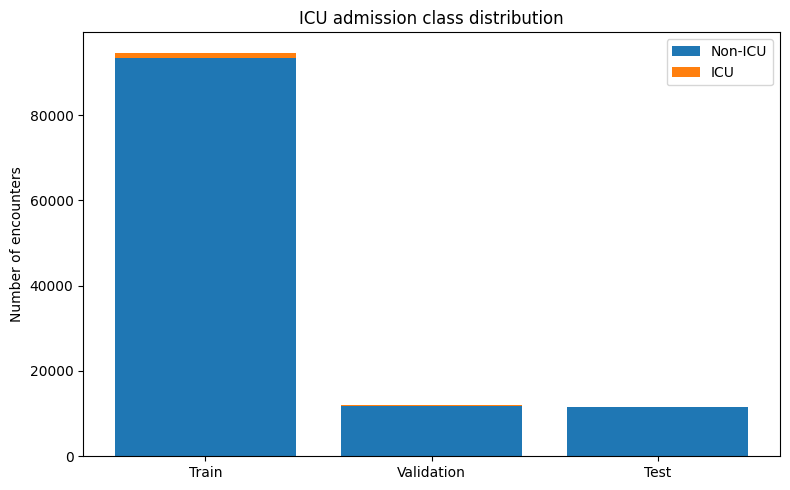

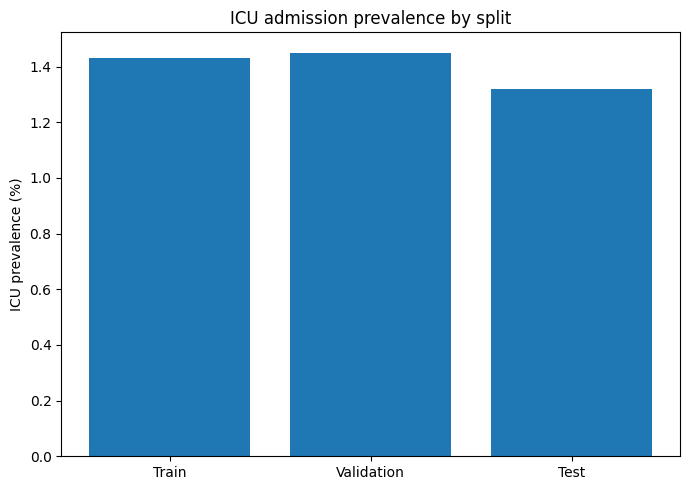

In [39]:
# ============================================================
# VISUALIZATION 2
# ICU CLASS DISTRIBUTION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

class_rows = []

for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    counts = frame["ICU_LABEL"].value_counts()

    class_rows.append({
        "Split": name,
        "Non-ICU": int(counts.get(0, 0)),
        "ICU": int(counts.get(1, 0)),
        "ICU prevalence (%)":
            100 * frame["ICU_LABEL"].mean()
    })

class_df = pd.DataFrame(class_rows)

display(class_df.round(2))


# Stacked bar
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    class_df["Split"],
    class_df["Non-ICU"],
    label="Non-ICU"
)

ax.bar(
    class_df["Split"],
    class_df["ICU"],
    bottom=class_df["Non-ICU"],
    label="ICU"
)

ax.set_ylabel("Number of encounters")
ax.set_title("ICU admission class distribution")
ax.legend()

plt.tight_layout()
plt.show()


# Prevalence
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    class_df["Split"],
    class_df["ICU prevalence (%)"]
)

ax.set_ylabel("ICU prevalence (%)")
ax.set_title("ICU admission prevalence by split")

plt.tight_layout()
plt.show()

## 3. Clean full-data LOS sequence construction

In [26]:
# ============================================================
# TEMPORAL / LOS DATASET SCHEMA DETECTION
# ============================================================

import numpy as np
import pandas as pd


print("=" * 70)
print("TEMPORAL DATA SCHEMA DETECTION")
print("=" * 70)


# ============================================================
# 1. CLEAN COLUMN NAMES
# ============================================================

numerics.columns = numerics.columns.astype(str).str.strip()
visits.columns = visits.columns.astype(str).str.strip()


print("\nNUMERICS COLUMNS:")
print(numerics.columns.tolist())

print("\nVISITS COLUMNS:")
print(visits.columns.tolist())


# ============================================================
# 2. DETECT NUMERIC TIMESTAMP COLUMN
# ============================================================

TIME_CANDIDATES = [
    "Recorded_time",
    "recorded_time",
    "Recorded_Time",
    "Time",
    "time",
    "TIME",
    "Timestamp",
    "timestamp",
    "DateTime",
    "datetime",
    "Date_Time",
    "date_time",
    "Measurement_time",
    "measurement_time",
    "MeasurementTime",
    "CHARTTIME",
    "charttime",
    "ChartTime",
    "Event_time",
    "event_time",
    "EventTime"
]


TIME_COL = next(
    (
        c
        for c in TIME_CANDIDATES
        if c in numerics.columns
    ),
    None
)


# ------------------------------------------------------------
# Fallback: search names containing time/date
# ------------------------------------------------------------

if TIME_COL is None:

    possible_time_cols = [
        c
        for c in numerics.columns
        if (
            "time" in c.lower()
            or "date" in c.lower()
        )
    ]

    print(
        "\nPossible timestamp columns:",
        possible_time_cols
    )

    if len(possible_time_cols) == 1:

        TIME_COL = possible_time_cols[0]

    elif len(possible_time_cols) > 1:

        # Prefer a column containing "record"
        preferred = [
            c
            for c in possible_time_cols
            if "record" in c.lower()
        ]

        if preferred:
            TIME_COL = preferred[0]
        else:
            TIME_COL = possible_time_cols[0]


if TIME_COL is None:

    raise KeyError(
        "\nCould not identify timestamp column.\n\n"
        f"Available numerics columns:\n"
        f"{numerics.columns.tolist()}"
    )


print(
    f"\n✓ Timestamp column selected: {TIME_COL}"
)


# ============================================================
# 3. DETECT NUMERICS FORMAT
#
# Two possibilities:
#
# WIDE:
# CSN | time | HR | RR | SpO2 | SBP ...
#
# LONG:
# CSN | time | Type/Name | Value
# ============================================================

WIDE_VITAL_ALIASES = {

    "HR": [
        "HR",
        "HeartRate",
        "Heart_Rate",
        "Heart Rate",
        "Pulse",
        "PulseRate"
    ],

    "RR": [
        "RR",
        "RespRate",
        "Resp_Rate",
        "RespiratoryRate",
        "Respiratory_Rate",
        "Respiratory Rate"
    ],

    "SpO2": [
        "SpO2",
        "SPO2",
        "spo2",
        "O2Sat",
        "O2_Sat",
        "OxygenSaturation",
        "Oxygen_Saturation"
    ],

    "SBP": [
        "SBP",
        "SystolicBP",
        "Systolic_BP",
        "Systolic",
        "NIBP_Systolic"
    ],

    "DBP": [
        "DBP",
        "DiastolicBP",
        "Diastolic_BP",
        "Diastolic",
        "NIBP_Diastolic"
    ],

    "Temp": [
        "Temp",
        "Temperature",
        "TEMP",
        "BodyTemp",
        "Body_Temperature"
    ],

    "MAP": [
        "MAP",
        "MeanBP",
        "Mean_BP",
        "MeanArterialPressure"
    ]
}


# ============================================================
# 4. SEARCH FOR WIDE-FORMAT VITALS
# ============================================================

wide_mapping = {}


for standard_name, aliases in WIDE_VITAL_ALIASES.items():

    for alias in aliases:

        if alias in numerics.columns:

            wide_mapping[standard_name] = alias

            break


print("\nWide-format vital mapping:")
print(wide_mapping)


# ============================================================
# 5. DECIDE WHETHER DATA IS WIDE OR LONG
# ============================================================

if len(wide_mapping) >= 3:

    NUMERICS_FORMAT = "wide"

else:

    NUMERICS_FORMAT = "long"


print(
    f"\nDetected numerics format: "
    f"{NUMERICS_FORMAT.upper()}"
)


# ============================================================
# 6A. WIDE FORMAT
# ============================================================

if NUMERICS_FORMAT == "wide":

    # Rename detected columns into standard names

    rename_map = {
        original: standard
        for standard, original
        in wide_mapping.items()
    }


    numerics_temporal = numerics.rename(
        columns=rename_map
    ).copy()


    VITALS = list(
        wide_mapping.keys()
    )


    print(
        "\n✓ Wide-format vital columns:"
    )

    print(VITALS)


# ============================================================
# 6B. LONG FORMAT
# ============================================================

else:

    print(
        "\nWide vital columns were not found."
    )

    print(
        "Attempting long-format detection..."
    )


    # --------------------------------------------------------
    # Detect measurement/type column
    # --------------------------------------------------------

    TYPE_CANDIDATES = [
        "Type",
        "type",
        "TYPE",
        "Name",
        "name",
        "NAME",
        "Variable",
        "variable",
        "VARIABLE",
        "Vital",
        "vital",
        "VitalType",
        "Vital_Type",
        "Measurement",
        "measurement",
        "Measure",
        "measure",
        "Signal",
        "signal",
        "Label",
        "label"
    ]


    TYPE_COL = next(
        (
            c
            for c in TYPE_CANDIDATES
            if c in numerics.columns
        ),
        None
    )


    # --------------------------------------------------------
    # Detect value column
    # --------------------------------------------------------

    VALUE_CANDIDATES = [
        "Value",
        "value",
        "VALUE",
        "NumericValue",
        "Numeric_Value",
        "numeric_value",
        "Result",
        "result",
        "RESULT",
        "MeasurementValue",
        "Measurement_Value",
        "measurement_value",
        "Val",
        "val"
    ]


    VALUE_COL = next(
        (
            c
            for c in VALUE_CANDIDATES
            if c in numerics.columns
        ),
        None
    )


    # --------------------------------------------------------
    # Show diagnostic information if exact names aren't found
    # --------------------------------------------------------

    if TYPE_COL is None:

        print(
            "\nCould not automatically identify "
            "measurement/type column."
        )

        print(
            "Available columns:"
        )

        print(
            numerics.columns.tolist()
        )


    if VALUE_COL is None:

        print(
            "\nCould not automatically identify "
            "measurement value column."
        )

        print(
            "Available columns:"
        )

        print(
            numerics.columns.tolist()
        )


    if TYPE_COL is None or VALUE_COL is None:

        print("\nSample numerics data:")

        display(
            numerics.head(20)
        )

        raise KeyError(
            "\nLong-format numerics detected, but "
            "measurement type/value columns could "
            "not be identified.\n\n"
            "Send the NUMERICS COLUMNS and first "
            "5 rows shown above."
        )


    print(
        f"\n✓ Measurement type column: "
        f"{TYPE_COL}"
    )

    print(
        f"✓ Measurement value column: "
        f"{VALUE_COL}"
    )


    # ========================================================
    # 7. INSPECT ACTUAL VITAL TYPES
    # ========================================================

    vital_types = (
        numerics[TYPE_COL]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
    )


    print("\n" + "=" * 70)
    print("MOST COMMON NUMERIC MEASUREMENT TYPES")
    print("=" * 70)

    display(
        vital_types.head(50)
    )


    # ========================================================
    # 8. MAP ACTUAL MEASUREMENT NAMES TO STANDARD VITALS
    # ========================================================

    VITAL_PATTERNS = {

        "HR": [
            "hr",
            "heart rate",
            "heartrate",
            "pulse"
        ],

        "RR": [
            "rr",
            "respiratory rate",
            "resp rate",
            "respiration rate"
        ],

        "SpO2": [
            "spo2",
            "oxygen saturation",
            "o2 sat",
            "pulse ox"
        ],

        "SBP": [
            "sbp",
            "systolic",
            "systolic bp"
        ],

        "DBP": [
            "dbp",
            "diastolic",
            "diastolic bp"
        ],

        "MAP": [
            "map",
            "mean arterial",
            "mean bp"
        ],

        "Temp": [
            "temp",
            "temperature"
        ]
    }


    available_types = (
        numerics[TYPE_COL]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()
    )


    vital_type_mapping = {}


    for standard, patterns in VITAL_PATTERNS.items():

        matches = []

        for actual in available_types:

            actual_lower = actual.lower()

            for pattern in patterns:

                if (
                    actual_lower == pattern
                    or pattern in actual_lower
                ):

                    matches.append(actual)

                    break


        if matches:

            vital_type_mapping[
                standard
            ] = matches[0]


    print("\nDetected vital mapping:")

    for standard, actual in vital_type_mapping.items():

        print(
            f"{standard:8s} <- {actual}"
        )


    if len(vital_type_mapping) < 3:

        print(
            "\n⚠ Fewer than three vital signs "
            "could be automatically mapped."
        )

        print(
            "\nActual measurement types:"
        )

        print(
            available_types[:100]
        )

        raise KeyError(
            "\nCould not confidently identify "
            "at least three vital signs.\n"
            "Use the measurement types printed "
            "above to create the mapping."
        )


    # ========================================================
    # 9. KEEP ONLY SELECTED VITALS
    # ========================================================

    reverse_mapping = {
        actual: standard
        for standard, actual
        in vital_type_mapping.items()
    }


    selected_types = list(
        reverse_mapping.keys()
    )


    temp_long = numerics[
        numerics[TYPE_COL]
        .astype(str)
        .str.strip()
        .isin(selected_types)
    ].copy()


    temp_long[
        "VITAL_STANDARD"
    ] = (
        temp_long[TYPE_COL]
        .astype(str)
        .str.strip()
        .map(reverse_mapping)
    )


    temp_long[
        VALUE_COL
    ] = pd.to_numeric(
        temp_long[VALUE_COL],
        errors="coerce"
    )


    temp_long = temp_long.dropna(
        subset=[
            "CSN",
            TIME_COL,
            "VITAL_STANDARD",
            VALUE_COL
        ]
    )


    # ========================================================
    # 10. CONVERT LONG -> WIDE
    # ========================================================

    numerics_temporal = (
        temp_long
        .pivot_table(
            index=[
                "CSN",
                TIME_COL
            ],
            columns="VITAL_STANDARD",
            values=VALUE_COL,
            aggfunc="mean"
        )
        .reset_index()
    )


    numerics_temporal.columns.name = None


    VITALS = [
        c
        for c in [
            "HR",
            "RR",
            "SpO2",
            "SBP",
            "DBP",
            "MAP",
            "Temp"
        ]
        if c in numerics_temporal.columns
    ]


# ============================================================
# 11. FINAL VITAL VALIDATION
# ============================================================

if len(VITALS) < 3:

    raise ValueError(
        f"""
Only {len(VITALS)} vital signs were identified.

Detected:
{VITALS}

At least three are required before proceeding.
"""
    )


print("\n" + "=" * 70)
print("TEMPORAL VITALS READY")
print("=" * 70)

print(
    "Vital columns:",
    VITALS
)

print(
    "Timestamp column:",
    TIME_COL
)

print(
    "Temporal table shape:",
    numerics_temporal.shape
)


display(
    numerics_temporal.head()
)


# ============================================================
# 12. DETECT LOS TARGET
# ============================================================

LOS_CANDIDATES = [
    "LOS_hours",
    "ED_LOS_hours",
    "ED_LOS",
    "Length_of_stay_hours",
    "Length_of_stay",
    "LengthOfStay",
    "los_hours",
    "LOS",
    "los"
]


LOS_COL = next(
    (
        c
        for c in LOS_CANDIDATES
        if c in visits.columns
    ),
    None
)


# ============================================================
# 13. DERIVE LOS IF EXPLICIT COLUMN DOES NOT EXIST
# ============================================================

vis_los = visits.copy()


if LOS_COL is None:

    print(
        "\nExplicit LOS column not found."
    )

    print(
        "Attempting to derive LOS from "
        "arrival/departure timestamps..."
    )


    ARRIVAL_CANDIDATES = [
        "Arrival_time",
        "arrival_time",
        "Arrival",
        "arrival",
        "ED_Arrival",
        "ED_Arrival_time",
        "ED_Arrival_Time",
        "ArrivalTime"
    ]


    DEPARTURE_CANDIDATES = [
        "Departure_time",
        "departure_time",
        "Departure",
        "departure",
        "ED_Departure",
        "ED_Departure_time",
        "ED_Departure_Time",
        "DepartureTime"
    ]


    ARR_COL = next(
        (
            c
            for c in ARRIVAL_CANDIDATES
            if c in vis_los.columns
        ),
        None
    )


    DEP_COL = next(
        (
            c
            for c in DEPARTURE_CANDIDATES
            if c in vis_los.columns
        ),
        None
    )


    if ARR_COL is None or DEP_COL is None:

        # Search for likely columns to make failure informative

        possible_arrival = [
            c
            for c in visits.columns
            if (
                "arriv" in c.lower()
                or "admit" in c.lower()
            )
        ]

        possible_departure = [
            c
            for c in visits.columns
            if (
                "depart" in c.lower()
                or "discharg" in c.lower()
            )
        ]


        print(
            "\nPossible arrival columns:"
        )

        print(
            possible_arrival
        )


        print(
            "\nPossible departure columns:"
        )

        print(
            possible_departure
        )


        raise KeyError(
            "\nNo explicit LOS target was found and "
            "arrival/departure columns could not be "
            "identified automatically."
        )


    print(
        f"\nArrival column: {ARR_COL}"
    )

    print(
        f"Departure column: {DEP_COL}"
    )


    vis_los[
        ARR_COL
    ] = pd.to_datetime(
        vis_los[ARR_COL],
        errors="coerce"
    )


    vis_los[
        DEP_COL
    ] = pd.to_datetime(
        vis_los[DEP_COL],
        errors="coerce"
    )


    vis_los[
        "LOS_hours"
    ] = (
        (
            vis_los[DEP_COL]
            -
            vis_los[ARR_COL]
        )
        .dt
        .total_seconds()
        /
        3600.0
    )


    LOS_COL = "LOS_hours"


# ============================================================
# 14. CONVERT LOS TO NUMERIC
# ============================================================

vis_los[
    LOS_COL
] = pd.to_numeric(
    vis_los[LOS_COL],
    errors="coerce"
)


# ============================================================
# 15. CLEAN LOS
# ============================================================

vis_los = (
    vis_los[
        [
            "CSN",
            LOS_COL
        ]
    ]
    .dropna()
    .copy()
)


vis_los = vis_los[
    np.isfinite(
        vis_los[LOS_COL]
    )
].copy()


vis_los = vis_los[
    vis_los[LOS_COL] >= 0
].copy()


# ============================================================
# 16. REMOVE DUPLICATE CSN TARGETS
# ============================================================

vis_los = (
    vis_los
    .drop_duplicates(
        subset=["CSN"],
        keep="first"
    )
    .reset_index(drop=True)
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("LOS / TEMPORAL CONFIGURATION")
print("=" * 70)


print(
    f"Numerics format: "
    f"{NUMERICS_FORMAT}"
)


print(
    f"Time column: "
    f"{TIME_COL}"
)


print(
    f"Vital signs: "
    f"{VITALS}"
)


print(
    f"LOS target: "
    f"{LOS_COL}"
)


print(
    f"Valid LOS encounters: "
    f"{len(vis_los):,}"
)


print(
    "\nLOS distribution (hours):"
)


display(
    vis_los[
        LOS_COL
    ].describe()
)


print(
    "\n✓ Temporal data schema detected."
)

print(
    "✓ Vital signs identified."
)

print(
    "✓ LOS target prepared."
)

print(
    "\nReady for 60-minute tensor construction."
)

TEMPORAL DATA SCHEMA DETECTION

NUMERICS COLUMNS:
['CSN', 'Source', 'Measure', 'Value', 'Time']

VISITS COLUMNS:
['MRN', 'CSN', 'Visit_no', 'Visits', 'Age', 'Gender', 'Race', 'Ethnicity', 'Means_of_arrival', 'Triage_Temp', 'Triage_HR', 'Triage_RR', 'Triage_SpO2', 'Triage_SBP', 'Triage_DBP', 'Triage_acuity', 'CC', 'ED_dispo', 'Hours_to_next_visit', 'Dispo_class_next_visit', 'ED_LOS', 'Hosp_LOS', 'DC_dispo', 'Payor_class', 'Admit_service', 'Dx_ICD9', 'Dx_ICD10', 'Dx_name', 'Arrival_time', 'Roomed_time', 'Dispo_time', 'Admit_time', 'Departure_time']

✓ Timestamp column selected: Time

Wide-format vital mapping:
{}

Detected numerics format: LONG

Wide vital columns were not found.
Attempting long-format detection...

✓ Measurement type column: Measure
✓ Measurement value column: Value

MOST COMMON NUMERIC MEASUREMENT TYPES


Measure
SpO2        10962881
Perf        10045629
HR           7781180
1min_HRV     7238695
RR           6715438
5min_HRV     1520936
SBP          1039072
DBP          1039072
MAP          1039072
Pain          233300
Temp          166529
LPM_O2         39704
Name: count, dtype: int64


Detected vital mapping:
HR       <- HR
RR       <- RR
SpO2     <- SpO2
SBP      <- SBP
DBP      <- DBP
MAP      <- MAP
Temp     <- Temp

TEMPORAL VITALS READY
Vital columns: ['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']
Timestamp column: Time
Temporal table shape: (11536056, 9)


,CSN,Time,DBP,HR,MAP,RR,SBP,SpO2,Temp
0,98972695,2266-06-10T19:06:35Z,60.0,94.000000,79.000000,18.000000,117.0,100.00000,98.1
1,98972695,2266-06-10T20:36:35Z,NaN,NaN,NaN,NaN,NaN,98.31250,NaN
2,98972695,2266-06-10T20:37:35Z,NaN,74.781250,NaN,21.250000,NaN,99.87931,NaN
3,98972695,2266-06-10T20:38:35Z,71.0,74.271186,87.666667,20.694915,121.0,100.00000,NaN
4,98972695,2266-06-10T20:39:35Z,NaN,75.931034,NaN,18.620690,NaN,100.00000,NaN



LOS / TEMPORAL CONFIGURATION
Numerics format: long
Time column: Time
Vital signs: ['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']
LOS target: ED_LOS
Valid LOS encounters: 118,153

LOS distribution (hours):


count    118153.000000
mean          6.047481
std           4.105006
min           0.020000
25%           3.720000
50%           5.350000
75%           7.400000
max         175.730000
Name: ED_LOS, dtype: float64


✓ Temporal data schema detected.
✓ Vital signs identified.
✓ LOS target prepared.

Ready for 60-minute tensor construction.


### 3.1 Build 60-minute tensors for **all** split encounters

For memory safety, arrays are `float32`. The builder aligns target values by CSN and returns only encounters with both a valid LOS target and numeric records.


In [ ]:
num = numerics[["CSN", TIME_COL] + VITALS].copy()

In [29]:
# ============================================================
# BUILD 60-MINUTE TEMPORAL TENSORS
# ============================================================

import numpy as np
import pandas as pd

T = 60

print("=" * 70)
print("BUILDING 60-MINUTE TEMPORAL TENSORS")
print("=" * 70)


# ============================================================
# 1. USE STANDARDIZED TEMPORAL TABLE
#
# IMPORTANT:
# numerics_temporal was created in the previous block.
# It contains standardized columns:
#
# CSN | TIME_COL | HR | RR | SpO2 | SBP | DBP | MAP | Temp
#
# depending on which vital signs were available.
# ============================================================

if "numerics_temporal" not in globals():

    raise RuntimeError(
        "numerics_temporal does not exist.\n"
        "Run the temporal schema-detection block first."
    )


print("\nAvailable temporal columns:")
print(numerics_temporal.columns.tolist())

print("\nRequested vital columns:")
print(VITALS)


# ============================================================
# 2. KEEP ONLY VITALS THAT ACTUALLY EXIST
# ============================================================

VITALS_AVAILABLE = [
    vital
    for vital in VITALS
    if vital in numerics_temporal.columns
]


missing_vitals = [
    vital
    for vital in VITALS
    if vital not in numerics_temporal.columns
]


print("\nVital signs available:")
print(VITALS_AVAILABLE)


if missing_vitals:

    print("\nVital signs not available:")
    print(missing_vitals)


if len(VITALS_AVAILABLE) < 3:

    raise ValueError(
        f"""
Only {len(VITALS_AVAILABLE)} usable vital signs were found.

Available:
{VITALS_AVAILABLE}

Temporal columns:
{numerics_temporal.columns.tolist()}
"""
    )


# From this point onward, only use valid columns
VITALS = VITALS_AVAILABLE


# ============================================================
# 3. VERIFY REQUIRED COLUMNS
# ============================================================

required_temporal_columns = [
    "CSN",
    TIME_COL
] + VITALS


missing_columns = [
    column
    for column in required_temporal_columns
    if column not in numerics_temporal.columns
]


if missing_columns:

    raise KeyError(
        f"""
Missing temporal columns:

{missing_columns}

Available columns:

{numerics_temporal.columns.tolist()}
"""
    )


# ============================================================
# 4. CREATE TEMPORAL WORKING TABLE
# ============================================================

num = numerics_temporal[
    required_temporal_columns
].copy()


print(
    "\nInitial temporal rows:",
    f"{len(num):,}"
)


# ============================================================
# 5. STANDARDIZE CSN
# ============================================================

num["CSN"] = (
    num["CSN"]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
)


vis_los["CSN"] = (
    vis_los["CSN"]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
)


split_train["CSN"] = (
    split_train["CSN"]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
)


split_val["CSN"] = (
    split_val["CSN"]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
)


split_test["CSN"] = (
    split_test["CSN"]
    .astype(str)
    .str.strip()
    .str.replace(".0", "", regex=False)
)


# ============================================================
# 6. CONVERT TIMESTAMP
# ============================================================

num[TIME_COL] = pd.to_datetime(
    num[TIME_COL],
    errors="coerce"
)


invalid_time_count = (
    num[TIME_COL]
    .isna()
    .sum()
)


print(
    "\nRows with invalid timestamps:",
    f"{invalid_time_count:,}"
)


num = (
    num
    .dropna(
        subset=[TIME_COL]
    )
    .copy()
)


# ============================================================
# 7. CONVERT VITAL VALUES TO NUMERIC
# ============================================================

for vital in VITALS:

    num[vital] = pd.to_numeric(
        num[vital],
        errors="coerce"
    )


# ============================================================
# 8. REMOVE ROWS WHERE ALL VITALS ARE MISSING
# ============================================================

before = len(num)


num = num.dropna(
    subset=VITALS,
    how="all"
).copy()


print(
    "Rows removed because all vitals were missing:",
    f"{before - len(num):,}"
)


# ============================================================
# 9. SORT BY PATIENT ENCOUNTER + TIME
# ============================================================

num = (
    num
    .sort_values(
        [
            "CSN",
            TIME_COL
        ]
    )
    .reset_index(drop=True)
)


print(
    "Usable temporal rows:",
    f"{len(num):,}"
)


print(
    "Unique temporal encounters:",
    f"{num['CSN'].nunique():,}"
)


# ============================================================
# 10. CLEAN LOS TARGET
# ============================================================

vis_los[LOS_COL] = pd.to_numeric(
    vis_los[LOS_COL],
    errors="coerce"
)


vis_los = (
    vis_los
    .dropna(
        subset=[
            "CSN",
            LOS_COL
        ]
    )
    .copy()
)


vis_los = vis_los[
    np.isfinite(
        vis_los[LOS_COL]
    )
].copy()


vis_los = vis_los[
    vis_los[LOS_COL] >= 0
].copy()


vis_los = (
    vis_los
    .drop_duplicates(
        subset=["CSN"],
        keep="first"
    )
    .reset_index(drop=True)
)


print(
    "Valid LOS encounters:",
    f"{len(vis_los):,}"
)


# ============================================================
# 11. CREATE ENCOUNTER GROUPS
# ============================================================

print("\nCreating encounter groups...")


groups = {
    csn: group.reset_index(drop=True)
    for csn, group
    in num.groupby(
        "CSN",
        sort=False
    )
}


print(
    "Temporal encounter groups:",
    f"{len(groups):,}"
)


# ============================================================
# 12. CREATE LOS LOOKUP
# ============================================================

los_map = dict(
    zip(
        vis_los["CSN"],
        vis_los[LOS_COL]
    )
)


print(
    "LOS lookup encounters:",
    f"{len(los_map):,}"
)


# ============================================================
# 13. CHECK MODALITY OVERLAP
# ============================================================

temporal_ids = set(
    groups.keys()
)


los_ids = set(
    los_map.keys()
)


usable_ids = (
    temporal_ids
    &
    los_ids
)


print("\n" + "=" * 70)
print("TEMPORAL / LOS OVERLAP")
print("=" * 70)


print(
    "Temporal encounters:",
    f"{len(temporal_ids):,}"
)


print(
    "LOS encounters:",
    f"{len(los_ids):,}"
)


print(
    "Encounters with both:",
    f"{len(usable_ids):,}"
)


# ============================================================
# 14. BUILD TENSOR FUNCTION
# ============================================================

def build_split_tensors(
    split_df,
    split_name="split",
    max_visits=None
):

    # --------------------------------------------------------
    # Split IDs
    # --------------------------------------------------------

    split_ids = (
        split_df["CSN"]
        .astype(str)
        .str.strip()
        .tolist()
    )


    # --------------------------------------------------------
    # Keep only encounters with:
    #
    # 1. temporal measurements
    # 2. valid LOS target
    # --------------------------------------------------------

    ids = [
        csn
        for csn in split_ids
        if (
            csn in groups
            and
            csn in los_map
        )
    ]


    print(
        f"\n{split_name}:"
    )

    print(
        "  Split encounters:",
        f"{len(split_ids):,}"
    )

    print(
        "  Temporal + LOS encounters:",
        f"{len(ids):,}"
    )


    # --------------------------------------------------------
    # Optional debugging only
    #
    # Camera-ready execution should leave max_visits=None.
    # --------------------------------------------------------

    if max_visits is not None:

        print(
            f"  ⚠ DEBUG MODE: "
            f"limiting to {max_visits:,} encounters"
        )

        ids = ids[:max_visits]


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(ids) == 0:

        raise ValueError(
            f"""
No usable encounters found for {split_name}.

Possible causes:
1. CSN types do not match.
2. LOS targets do not overlap with numerics.
3. Split IDs do not match dataset IDs.
"""
        )


    X = []
    M = []
    D = []
    y = []
    kept = []


    # ========================================================
    # PROCESS EACH ENCOUNTER
    # ========================================================

    for index, csn in enumerate(ids):

        g = groups[csn].copy()


        # ----------------------------------------------------
        # Ensure chronological ordering
        # ----------------------------------------------------

        g = (
            g
            .sort_values(TIME_COL)
            .reset_index(drop=True)
        )


        # ----------------------------------------------------
        # First available numeric measurement defines t=0
        # ----------------------------------------------------

        t0 = g[
            TIME_COL
        ].iloc[0]


        # ----------------------------------------------------
        # Minutes since first observation
        # ----------------------------------------------------

        minutes_float = (
            (
                g[TIME_COL]
                -
                t0
            )
            .dt
            .total_seconds()
            /
            60.0
        ).to_numpy()


        # ----------------------------------------------------
        # Keep first 60 minutes only
        # ----------------------------------------------------

        keep_mask = (
            (minutes_float >= 0)
            &
            (minutes_float < T)
        )


        g_window = (
            g.loc[
                keep_mask
            ]
            .copy()
        )


        minutes_window = (
            minutes_float[
                keep_mask
            ]
        )


        # ----------------------------------------------------
        # Skip empty encounter
        # ----------------------------------------------------

        if len(g_window) == 0:

            continue


        # ----------------------------------------------------
        # Convert continuous minutes to minute bins
        #
        # Example:
        # 0.3 min -> bin 0
        # 5.8 min -> bin 5
        # ----------------------------------------------------

        minute_bins = np.floor(
            minutes_window
        ).astype(int)


        minute_bins = np.clip(
            minute_bins,
            0,
            T - 1
        )


        # ----------------------------------------------------
        # Initialize tensor
        #
        # T × number_of_vitals
        # ----------------------------------------------------

        x = np.full(
            (
                T,
                len(VITALS)
            ),
            np.nan,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Extract vital matrix
        # ----------------------------------------------------

        vital_matrix = (
            g_window[VITALS]
            .to_numpy(
                dtype=np.float32
            )
        )


        # ----------------------------------------------------
        # Fill minute bins
        #
        # If multiple observations occur during the same
        # minute, later available measurements overwrite
        # earlier values for that vital.
        # ----------------------------------------------------

        for minute, row in zip(
            minute_bins,
            vital_matrix
        ):

            valid = np.isfinite(
                row
            )


            x[
                minute,
                valid
            ] = row[
                valid
            ]


        # ----------------------------------------------------
        # Missingness mask
        #
        # 1 = observed
        # 0 = missing
        # ----------------------------------------------------

        m = np.isfinite(
            x
        ).astype(
            np.float32
        )


        # ----------------------------------------------------
        # Time-since-last-observation tensor
        # ----------------------------------------------------

        d = np.zeros_like(
            x,
            dtype=np.float32
        )


        for vital_index in range(
            x.shape[1]
        ):

            gap = 0.0


            for minute in range(T):

                if m[
                    minute,
                    vital_index
                ] == 1:

                    gap = 0.0

                else:

                    gap += 1.0


                d[
                    minute,
                    vital_index
                ] = gap


        # ----------------------------------------------------
        # Validate LOS target
        # ----------------------------------------------------

        target = float(
            los_map[csn]
        )


        if not np.isfinite(
            target
        ):

            continue


        if target < 0:

            continue


        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        X.append(
            x
        )

        M.append(
            m
        )

        D.append(
            d
        )

        y.append(
            target
        )

        kept.append(
            csn
        )


        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            (index + 1) % 10000 == 0
        ):

            print(
                f"  Processed "
                f"{index + 1:,} / "
                f"{len(ids):,}"
            )


    # ========================================================
    # FINAL SAFETY CHECK
    # ========================================================

    if len(X) == 0:

        raise ValueError(
            f"No tensors generated for {split_name}."
        )


    # ========================================================
    # STACK ARRAYS
    # ========================================================

    X = np.stack(
        X
    ).astype(
        np.float32
    )


    M = np.stack(
        M
    ).astype(
        np.float32
    )


    D = np.stack(
        D
    ).astype(
        np.float32
    )


    y = np.asarray(
        y,
        dtype=np.float32
    )


    kept = np.asarray(
        kept
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    print(
        "  Final tensor shape:",
        X.shape
    )

    print(
        "  Mask shape:",
        M.shape
    )

    print(
        "  Delta shape:",
        D.shape
    )

    print(
        "  Target shape:",
        y.shape
    )


    observed_fraction = (
        M.mean()
    )


    print(
        "  Observed measurement fraction:",
        f"{observed_fraction:.4f}"
    )


    print(
        "  Missing measurement fraction:",
        f"{1 - observed_fraction:.4f}"
    )


    return (
        X,
        M,
        D,
        y,
        kept
    )


# ============================================================
# 15. BUILD FULL TRAINING DATA
#
# IMPORTANT:
#
# NO [:100]
# NO max_visits=100
#
# We use the complete available training split.
# ============================================================

print("\n" + "=" * 70)
print("BUILDING TRAINING TENSORS")
print("=" * 70)


Xt_tr, M_tr, D_tr, y_tr, csn_tr = (
    build_split_tensors(
        split_train,
        split_name="TRAIN",
        max_visits=None
    )
)


# ============================================================
# 16. BUILD VALIDATION DATA
# ============================================================

print("\n" + "=" * 70)
print("BUILDING VALIDATION TENSORS")
print("=" * 70)


Xt_va, M_va, D_va, y_va, csn_va = (
    build_split_tensors(
        split_val,
        split_name="VALIDATION",
        max_visits=None
    )
)


# ============================================================
# 17. BUILD TEST DATA
# ============================================================

print("\n" + "=" * 70)
print("BUILDING TEST TENSORS")
print("=" * 70)


Xt_te, M_te, D_te, y_te, csn_te = (
    build_split_tensors(
        split_test,
        split_name="TEST",
        max_visits=None
    )
)


# ============================================================
# 18. FINAL SHAPE SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEMPORAL DATASET")
print("=" * 70)


print(
    "Vital signs:"
)

print(
    VITALS
)


print(
    "\nNumber of vital signs:",
    len(VITALS)
)


print(
    "\nTRAIN"
)

print(
    "X:",
    Xt_tr.shape
)

print(
    "M:",
    M_tr.shape
)

print(
    "D:",
    D_tr.shape
)

print(
    "y:",
    y_tr.shape
)


print(
    "\nVALIDATION"
)

print(
    "X:",
    Xt_va.shape
)

print(
    "M:",
    M_va.shape
)

print(
    "D:",
    D_va.shape
)

print(
    "y:",
    y_va.shape
)


print(
    "\nTEST"
)

print(
    "X:",
    Xt_te.shape
)

print(
    "M:",
    M_te.shape
)

print(
    "D:",
    D_te.shape
)

print(
    "y:",
    y_te.shape
)


# ============================================================
# 19. VERIFY ALIGNMENT
# ============================================================

assert (
    len(Xt_tr)
    ==
    len(y_tr)
    ==
    len(csn_tr)
)

assert (
    len(Xt_va)
    ==
    len(y_va)
    ==
    len(csn_va)
)

assert (
    len(Xt_te)
    ==
    len(y_te)
    ==
    len(csn_te)
)


print(
    "\n✓ Tensor / target / CSN alignment confirmed."
)


# ============================================================
# 20. CHECK SPLIT LEAKAGE AGAIN
# ============================================================

train_tensor_ids = set(
    csn_tr.astype(str)
)

val_tensor_ids = set(
    csn_va.astype(str)
)

test_tensor_ids = set(
    csn_te.astype(str)
)


assert len(
    train_tensor_ids
    &
    val_tensor_ids
) == 0


assert len(
    train_tensor_ids
    &
    test_tensor_ids
) == 0


assert len(
    val_tensor_ids
    &
    test_tensor_ids
) == 0


print(
    "✓ No CSN overlap between tensor splits."
)


# ============================================================
# 21. LOS SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("LOS TARGET SUMMARY")
print("=" * 70)


print("\nTraining LOS:")

print(
    pd.Series(
        y_tr
    ).describe()
)


print("\nValidation LOS:")

print(
    pd.Series(
        y_va
    ).describe()
)


print("\nTest LOS:")

print(
    pd.Series(
        y_te
    ).describe()
)


# ============================================================
# 22. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("TENSOR CONSTRUCTION COMPLETE")
print("=" * 70)


print(
    "\n✓ Full training split used."
)

print(
    "✓ No 100-encounter truncation."
)

print(
    "✓ 60-minute temporal window constructed."
)

print(
    "✓ Missingness masks constructed."
)

print(
    "✓ Time-since-last-observation tensors constructed."
)

print(
    "✓ LOS targets aligned by CSN."
)

print(
    "\nReady for training-only normalization "
    "and GRU / GRU-D training."
)

BUILDING 60-MINUTE TEMPORAL TENSORS

Available temporal columns:
['CSN', 'Time', 'DBP', 'HR', 'MAP', 'RR', 'SBP', 'SpO2', 'Temp']

Requested vital columns:
['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']

Vital signs available:
['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']

Initial temporal rows: 11,536,056

Rows with invalid timestamps: 4,468,877
Rows removed because all vitals were missing: 0
Usable temporal rows: 7,067,179
Unique temporal encounters: 62,241
Valid LOS encounters: 118,153

Creating encounter groups...
Temporal encounter groups: 62,241
LOS lookup encounters: 118,153

TEMPORAL / LOS OVERLAP
Temporal encounters: 62,241
LOS encounters: 118,153
Encounters with both: 62,143

BUILDING TRAINING TENSORS

TRAIN:
  Split encounters: 94,657
  Temporal + LOS encounters: 49,725
  Processed 10,000 / 49,725
  Processed 20,000 / 49,725
  Processed 30,000 / 49,725
  Processed 40,000 / 49,725
  Final tensor shape: (49725, 60, 7)
  Mask shape: (49725, 60, 7)
  Delta shape: (49725, 

### 3.2 Training-only normalization and missing-value representation

In [31]:
# Training statistics from observed values only
means=np.nanmean(Xt_tr,axis=(0,1)).astype(np.float32)
stds=np.nanstd(Xt_tr,axis=(0,1)).astype(np.float32)
stds=np.where(stds<1e-6,1.0,stds).astype(np.float32)

def normalize(X):
    Z=(X-means)/stds
    # Missing entries become 0 after standardization; mask tells model they are missing
    return np.nan_to_num(Z,nan=0.0,posinf=0.0,neginf=0.0).astype(np.float32)

Xt_tr=normalize(Xt_tr); Xt_va=normalize(Xt_va); Xt_te=normalize(Xt_te)

assert np.isfinite(Xt_tr).all() and np.isfinite(y_tr).all()
assert np.isfinite(Xt_va).all() and np.isfinite(y_va).all()
assert np.isfinite(Xt_te).all() and np.isfinite(y_te).all()


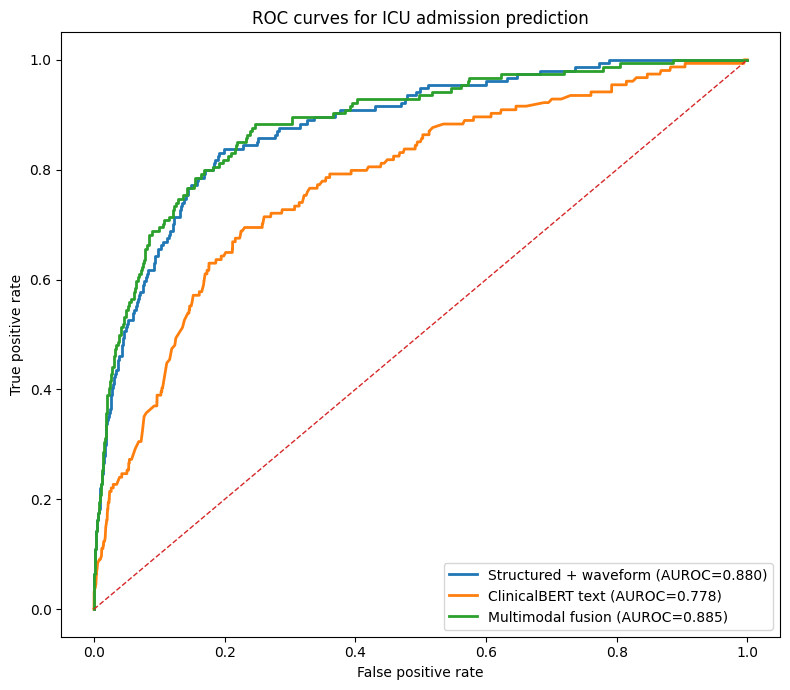

,Model,AUROC
2,Multimodal fusion,0.8853
0,Structured + waveform,0.8795
1,ClinicalBERT text,0.7781


In [40]:
# ============================================================
# VISUALIZATION 3
# ROC CURVES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

y_test = test_df["ICU_LABEL"].to_numpy()


# ------------------------------------------------------------
# Collect available predictions automatically
# ------------------------------------------------------------

models = {}

if "p_vitals_test" in globals():
    models["Vitals only"] = p_vitals_test

if "p_struct_test" in globals():
    models["Structured only"] = p_struct_test

if "p_sw_test" in globals():
    models["Structured + waveform"] = p_sw_test

if "p_t_test" in globals():
    models["ClinicalBERT text"] = p_t_test

if "p_fusion_test" in globals():
    models["Multimodal fusion"] = p_fusion_test

elif "fusion_test_probs" in globals():
    models["Multimodal fusion"] = fusion_test_probs

elif (
    "p_sw_test" in globals()
    and "p_t_test" in globals()
    and "W_SW" in globals()
    and "W_TEXT" in globals()
):
    models["Multimodal fusion"] = (
        W_SW * p_sw_test
        +
        W_TEXT * p_t_test
    )


if not models:
    raise RuntimeError(
        "No classification test probabilities found."
    )


fig, ax = plt.subplots(figsize=(8, 7))

results = []

for name, probs in models.items():

    probs = np.asarray(probs)

    if len(probs) != len(y_test):
        print(
            f"Skipping {name}: "
            f"{len(probs)} predictions vs {len(y_test)} labels"
        )
        continue

    fpr, tpr, _ = roc_curve(
        y_test,
        probs
    )

    auc = roc_auc_score(
        y_test,
        probs
    )

    results.append({
        "Model": name,
        "AUROC": auc
    })

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUROC={auc:.3f})"
    )


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves for ICU admission prediction")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


roc_results = pd.DataFrame(
    results
).sort_values(
    "AUROC",
    ascending=False
)

display(
    roc_results.round(4)
)

## 4. GRU and GRU-D LOS baselines

In [32]:
class SeqDataset(Dataset):
    def __init__(self,X,M,D,y):
        self.X=torch.from_numpy(X)
        self.M=torch.from_numpy(M)
        self.D=torch.from_numpy(D)
        self.y=torch.from_numpy(y)
    def __len__(self): return len(self.y)
    def __getitem__(self,i):
        return self.X[i],self.M[i],self.D[i],self.y[i]

BATCH=256 if torch.cuda.is_available() else 64
tr_loader=DataLoader(SeqDataset(Xt_tr,M_tr,D_tr,y_tr),batch_size=BATCH,shuffle=True)
va_loader=DataLoader(SeqDataset(Xt_va,M_va,D_va,y_va),batch_size=BATCH,shuffle=False)
te_loader=DataLoader(SeqDataset(Xt_te,M_te,D_te,y_te),batch_size=BATCH,shuffle=False)

class GRUBaseline(nn.Module):
    def __init__(self,d,h=64):
        super().__init__()
        self.gru=nn.GRU(d,h,batch_first=True)
        self.fc=nn.Linear(h,1)
    def forward(self,X,M=None,D=None):
        _,h=self.gru(X)
        return self.fc(h[-1]).squeeze(-1)

class GRUD(nn.Module):
    def __init__(self,d,h=64):
        super().__init__()
        self.h=h
        self.gamma_x=nn.Linear(d,d)
        self.gamma_h=nn.Linear(d,h)
        self.cell=nn.GRUCell(d*2,h)
        self.fc=nn.Linear(h,1)
    def forward(self,X,M,D,return_hidden=False):
        B,T,d=X.shape
        h=torch.zeros(B,self.h,device=X.device)
        x_prev=torch.zeros(B,d,device=X.device)
        for t in range(T):
            gx=torch.exp(-torch.relu(self.gamma_x(D[:,t])))
            gh=torch.exp(-torch.relu(self.gamma_h(D[:,t])))
            xhat=M[:,t]*X[:,t] + (1-M[:,t])*(gx*x_prev)
            h=gh*h
            h=self.cell(torch.cat([xhat,M[:,t]],dim=1),h)
            x_prev=xhat
        if return_hidden: return h
        return self.fc(h).squeeze(-1)

def eval_reg(model,loader):
    model.eval(); pp=[]; yy=[]
    with torch.no_grad():
        for X,M,D,y in loader:
            X,M,D=X.to(DEVICE),M.to(DEVICE),D.to(DEVICE)
            p=model(X,M,D)
            pp.append(p.cpu().numpy()); yy.append(y.numpy())
    p=np.concatenate(pp); y=np.concatenate(yy)
    if not np.isfinite(p).all():
        raise FloatingPointError("Non-finite predictions detected; metrics aborted.")
    return np.sqrt(mean_squared_error(y,p)), mean_absolute_error(y,p), p, y

def train_reg(model,epochs=20,patience=4):
    model=model.to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    loss_fn=nn.SmoothL1Loss()
    best=np.inf; bad=0; best_state=None
    for ep in range(1,epochs+1):
        model.train(); losses=[]
        for X,M,D,y in tr_loader:
            X,M,D,y=X.to(DEVICE),M.to(DEVICE),D.to(DEVICE),y.to(DEVICE)
            opt.zero_grad()
            p=model(X,M,D)
            if not torch.isfinite(p).all():
                raise FloatingPointError("Non-finite training prediction.")
            loss=loss_fn(p,y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.0)
            opt.step()
            losses.append(loss.item())
        vrmse,vmae,_,_=eval_reg(model,va_loader)
        print(f"Epoch {ep:02d} train={np.mean(losses):.4f} val_RMSE={vrmse:.4f} val_MAE={vmae:.4f}")
        if vrmse < best-1e-4:
            best=vrmse; bad=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            bad+=1
            if bad>=patience: break
    model.load_state_dict(best_state)
    return model

gru=train_reg(GRUBaseline(len(VITALS)))
grud=train_reg(GRUD(len(VITALS)))

gru_rmse,gru_mae,gru_p,los_y=eval_reg(gru,te_loader)
grud_rmse,grud_mae,grud_p,_=eval_reg(grud,te_loader)

los_results=pd.DataFrame([
    ["GRU",gru_mae,gru_rmse],
    ["GRU-D",grud_mae,grud_rmse]
],columns=["Model","MAE_hours","RMSE_hours"])
display(los_results)
los_results.to_csv(OUT/"los_results.csv",index=False)
torch.save(grud.state_dict(),OUT/"grud_los.pt")


Epoch 01 train=2.3628 val_RMSE=3.7005 val_MAE=2.3476
Epoch 02 train=1.8659 val_RMSE=3.6789 val_MAE=2.3466
Epoch 03 train=1.8591 val_RMSE=3.6882 val_MAE=2.3143
Epoch 04 train=1.8308 val_RMSE=3.6655 val_MAE=2.2908
Epoch 05 train=1.8238 val_RMSE=3.6347 val_MAE=2.3045
Epoch 06 train=1.8226 val_RMSE=3.6882 val_MAE=2.2885
Epoch 07 train=1.8190 val_RMSE=3.6577 val_MAE=2.2888
Epoch 08 train=1.8162 val_RMSE=3.6524 val_MAE=2.2864
Epoch 09 train=1.8167 val_RMSE=3.6731 val_MAE=2.2818
Epoch 01 train=2.4783 val_RMSE=3.6994 val_MAE=2.3348
Epoch 02 train=1.8510 val_RMSE=3.6884 val_MAE=2.3163
Epoch 03 train=1.8295 val_RMSE=3.6910 val_MAE=2.3057
Epoch 04 train=1.8195 val_RMSE=3.6383 val_MAE=2.2963
Epoch 05 train=1.8137 val_RMSE=3.6562 val_MAE=2.2857
Epoch 06 train=1.8052 val_RMSE=3.6206 val_MAE=2.2995
Epoch 07 train=1.8044 val_RMSE=3.6304 val_MAE=2.2885
Epoch 08 train=1.8036 val_RMSE=3.6407 val_MAE=2.2827
Epoch 09 train=1.7983 val_RMSE=3.6723 val_MAE=2.2760
Epoch 10 train=1.7967 val_RMSE=3.6413 val_MAE=

,Model,MAE_hours,RMSE_hours
0,GRU,2.321137,3.927187
1,GRU-D,2.310981,3.916680


,Metric,Value
0,Accuracy,0.9870
1,Sensitivity,0.0649
2,Specificity,0.9993
3,Precision,0.5556
4,F1-score,0.1163
5,Threshold,0.4400


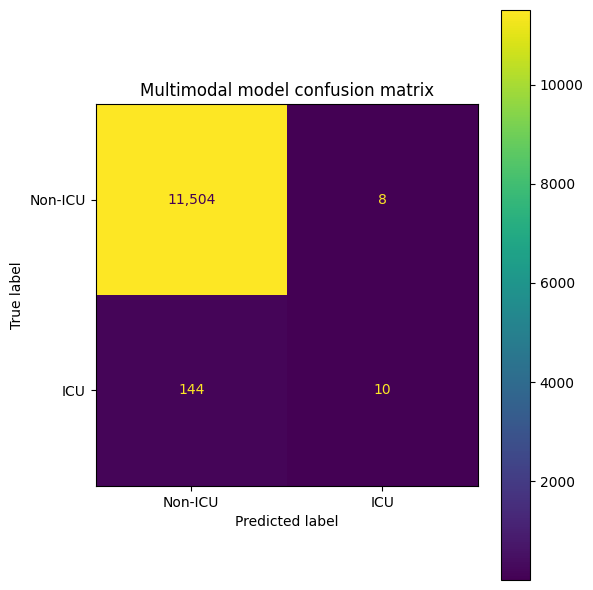

In [41]:
# ============================================================
# VISUALIZATION 4
# CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Get final fusion probabilities

if "p_fusion_test" in globals():

    final_probs = np.asarray(
        p_fusion_test
    )

elif "fusion_test_probs" in globals():

    final_probs = np.asarray(
        fusion_test_probs
    )

elif (
    "p_sw_test" in globals()
    and
    "p_t_test" in globals()
):

    final_probs = (
        W_SW * p_sw_test
        +
        W_TEXT * p_t_test
    )

else:

    raise RuntimeError(
        "Final fusion probabilities not found."
    )


y_true = test_df[
    "ICU_LABEL"
].to_numpy()


y_pred = (
    final_probs >= THRESHOLD
).astype(int)


cm = confusion_matrix(
    y_true,
    y_pred
)

tn, fp, fn, tp = cm.ravel()


sensitivity = (
    tp / (tp + fn)
)

specificity = (
    tn / (tn + fp)
)


metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1-score",
        "Threshold"
    ],

    "Value": [
        accuracy_score(y_true, y_pred),
        sensitivity,
        specificity,
        precision_score(y_true, y_pred),
        f1_score(y_true, y_pred),
        THRESHOLD
    ]
})


display(
    metrics.round(4)
)


fig, ax = plt.subplots(figsize=(6, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-ICU",
        "ICU"
    ]
)

disp.plot(
    ax=ax,
    values_format=","
)

ax.set_title(
    "Multimodal model confusion matrix"
)

plt.tight_layout()
plt.show()

## 5. Bootstrap uncertainty for LOS

In [33]:
def bootstrap_reg(y,p,n_boot=1000,seed=SEED):
    rng=np.random.default_rng(seed); maes=[]; rmses=[]; n=len(y)
    for _ in range(n_boot):
        idx=rng.integers(0,n,n)
        maes.append(mean_absolute_error(y[idx],p[idx]))
        rmses.append(np.sqrt(mean_squared_error(y[idx],p[idx])))
    return {
        "MAE_low":np.percentile(maes,2.5),
        "MAE_high":np.percentile(maes,97.5),
        "RMSE_low":np.percentile(rmses,2.5),
        "RMSE_high":np.percentile(rmses,97.5)
    }

for name,p in [("GRU",gru_p),("GRU-D",grud_p)]:
    print(name, bootstrap_reg(los_y,p))


GRU {'MAE_low': np.float64(2.240147751569748), 'MAE_high': np.float64(2.406144565343857), 'RMSE_low': np.float64(3.3913915490127584), 'RMSE_high': np.float64(4.507564652296792)}
GRU-D {'MAE_low': np.float64(2.230951863527298), 'MAE_high': np.float64(2.3947316527366636), 'RMSE_low': np.float64(3.378360909401115), 'RMSE_high': np.float64(4.497136270416587)}


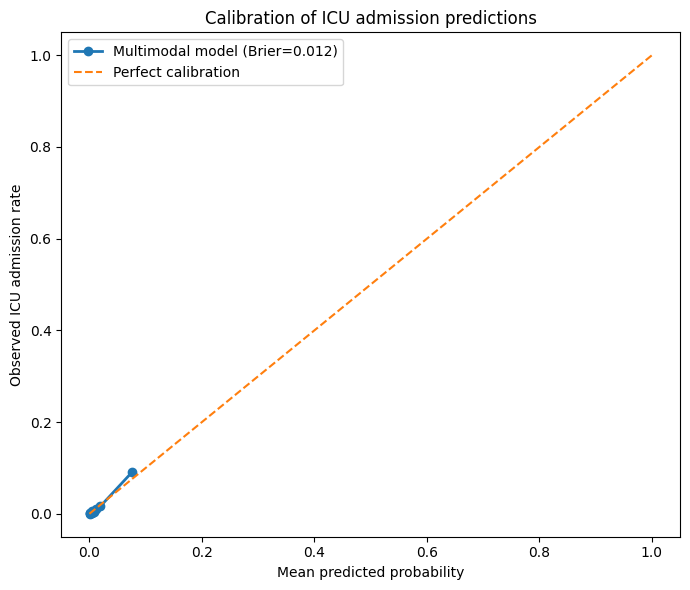

Brier score: 0.0118


In [42]:
# ============================================================
# VISUALIZATION 5
# CALIBRATION CURVE
# ============================================================

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


prob_true, prob_pred = calibration_curve(
    y_true,
    final_probs,
    n_bins=10,
    strategy="quantile"
)


brier = brier_score_loss(
    y_true,
    final_probs
)


fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label=f"Multimodal model (Brier={brier:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed ICU admission rate")
ax.set_title("Calibration of ICU admission predictions")
ax.legend()

plt.tight_layout()
plt.show()

print(
    f"Brier score: {brier:.4f}"
)

## 6. Save reproducibility metadata

In [35]:
# ============================================================
# SELECT CLASSIFICATION THRESHOLD USING VALIDATION SET ONLY
# ============================================================

import numpy as np
from sklearn.metrics import accuracy_score

print("=" * 70)
print("VALIDATION-BASED CLASSIFICATION THRESHOLD")
print("=" * 70)


# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

# The fused validation probabilities should already have been
# generated by the classification/fusion block.
#
# Support a few possible variable names from earlier cells.
# ============================================================

if "p_fusion_val" in globals():

    val_probs = p_fusion_val

elif "fusion_val_probs" in globals():

    val_probs = fusion_val_probs

elif "p_fused_val" in globals():

    val_probs = p_fused_val

elif (
    "p_sw_val" in globals()
    and
    "p_t_val" in globals()
    and
    "W_SW" in globals()
    and
    "W_TEXT" in globals()
):

    # Reconstruct fused validation probabilities
    val_probs = (
        W_SW * p_sw_val
        +
        W_TEXT * p_t_val
    )

else:

    raise NameError(
        """
Could not find fused validation probabilities.

Expected one of:
    p_fusion_val
    fusion_val_probs
    p_fused_val

OR all of:
    p_sw_val
    p_t_val
    W_SW
    W_TEXT

Run the classification fusion cell before this cell.
"""
    )


# ============================================================
# GET VALIDATION LABELS
# ============================================================

if "val_df" not in globals():

    raise NameError(
        "val_df is not defined. "
        "Run the classification preprocessing cell first."
    )


if "ICU_LABEL" not in val_df.columns:

    raise KeyError(
        "ICU_LABEL is missing from val_df."
    )


y_val_class = (
    val_df["ICU_LABEL"]
    .astype(int)
    .to_numpy()
)


val_probs = np.asarray(
    val_probs,
    dtype=float
)


# ============================================================
# VERIFY ALIGNMENT
# ============================================================

if len(y_val_class) != len(val_probs):

    raise ValueError(
        f"""
Validation label/probability mismatch.

Labels:
{len(y_val_class)}

Probabilities:
{len(val_probs)}
"""
    )


if not np.all(
    np.isfinite(val_probs)
):

    raise ValueError(
        "Validation probabilities contain NaN or infinity."
    )


# ============================================================
# SEARCH THRESHOLD
#
# Threshold is selected ONLY on validation data.
# Test labels are not used here.
# ============================================================

threshold_grid = np.arange(
    0.05,
    0.951,
    0.005
)


best_threshold = None
best_accuracy = -1.0


for threshold in threshold_grid:

    predictions = (
        val_probs >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_val_class,
        predictions
    )

    if accuracy > best_accuracy:

        best_accuracy = accuracy
        best_threshold = threshold


# ============================================================
# DEFINE THE VARIABLE EXPECTED BY FINAL CELL
# ============================================================

THRESHOLD = float(
    best_threshold
)


print(
    f"\nSelected threshold: "
    f"{THRESHOLD:.3f}"
)

print(
    f"Validation accuracy: "
    f"{best_accuracy:.4f}"
)


# ============================================================
# OPTIONAL TEST APPLICATION
#
# We APPLY the threshold to test predictions.
# We do NOT optimize it on test data.
# ============================================================

if "p_fusion_test" in globals():

    test_probs = np.asarray(
        p_fusion_test,
        dtype=float
    )

elif "fusion_test_probs" in globals():

    test_probs = np.asarray(
        fusion_test_probs,
        dtype=float
    )

elif "p_fused_test" in globals():

    test_probs = np.asarray(
        p_fused_test,
        dtype=float
    )

elif (
    "p_sw_test" in globals()
    and
    "p_t_test" in globals()
    and
    "W_SW" in globals()
    and
    "W_TEXT" in globals()
):

    test_probs = (
        W_SW * p_sw_test
        +
        W_TEXT * p_t_test
    )

else:

    test_probs = None


if test_probs is not None:

    test_predictions = (
        test_probs >= THRESHOLD
    ).astype(int)

    print(
        "\n✓ Validation-derived threshold "
        "is ready for held-out test evaluation."
    )


print("\n" + "=" * 70)
print("THRESHOLD SELECTION COMPLETE")
print("=" * 70)

print(
    f"THRESHOLD = {THRESHOLD:.3f}"
)

VALIDATION-BASED CLASSIFICATION THRESHOLD

Selected threshold: 0.440
Validation accuracy: 0.9858

✓ Validation-derived threshold is ready for held-out test evaluation.

THRESHOLD SELECTION COMPLETE
THRESHOLD = 0.440


In [37]:
metadata = {
    "seed": SEED,
    "text_model": TEXT_MODEL,
    "text_max_length": MAX_LEN,
    "xgboost": XGB_PARAMS,
    "fusion_weight_structured_wave": W_SW,
    "fusion_weight_text": W_TEXT,
    "classification_threshold_from_validation": THRESHOLD,
    "vital_columns": VITALS,
    "waveform_features": WAVE_COLS,
    "structured_features": STRUCT_COLS,
    "los_time_window_minutes": T,
    "classification_train_n": int(len(train_df)),
    "classification_val_n": int(len(val_df)),
    "classification_test_n": int(len(test_df)),
    "los_train_n": int(len(y_tr)),
    "los_val_n": int(len(y_va)),
    "los_test_n": int(len(y_te))
}
with open(OUT/"run_metadata.json","w") as f:
    json.dump(metadata,f,indent=2)

print("Saved outputs:")
for p in sorted(OUT.iterdir()):
    print(" -",p.name)


Saved outputs:
 - bert_test.npy
 - bert_test_csn.npy
 - bert_train.npy
 - bert_train_csn.npy
 - bert_val.npy
 - bert_val_csn.npy
 - grud_los.pt
 - los_results.csv
 - run_metadata.json


,Structured/Waveform weight,Text weight,Validation AUROC
0,1.00,0.00,0.8964
1,0.95,0.05,0.9018
2,0.90,0.10,0.9041
3,0.85,0.15,0.9052
4,0.80,0.20,0.9056
5,0.75,0.25,0.9056
6,0.70,0.30,0.9052
7,0.65,0.35,0.9044
8,0.60,0.40,0.9029
9,0.55,0.45,0.9012


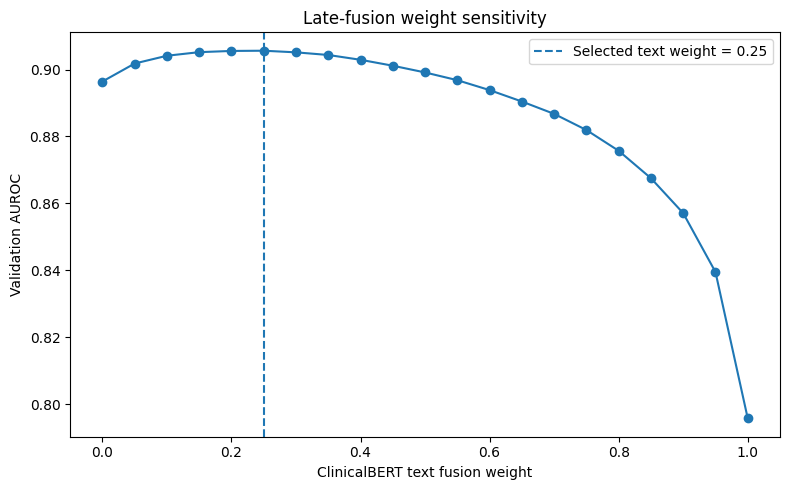

In [43]:
# ============================================================
# VISUALIZATION 6
# FUSION WEIGHT SENSITIVITY
# VALIDATION DATA ONLY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score


if (
    "p_sw_val" not in globals()
    or
    "p_t_val" not in globals()
):

    raise RuntimeError(
        "p_sw_val and p_t_val are required."
    )


y_val = val_df[
    "ICU_LABEL"
].to_numpy()


weights = np.arange(
    0.0,
    1.01,
    0.05
)


weight_results = []


for w_text in weights:

    w_sw = 1.0 - w_text

    probs = (
        w_sw * p_sw_val
        +
        w_text * p_t_val
    )

    auc = roc_auc_score(
        y_val,
        probs
    )

    weight_results.append({
        "Structured/Waveform weight": w_sw,
        "Text weight": w_text,
        "Validation AUROC": auc
    })


weight_df = pd.DataFrame(
    weight_results
)


display(
    weight_df.round(4)
)


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    weight_df["Text weight"],
    weight_df["Validation AUROC"],
    marker="o"
)

ax.axvline(
    W_TEXT,
    linestyle="--",
    label=f"Selected text weight = {W_TEXT:.2f}"
)

ax.set_xlabel("ClinicalBERT text fusion weight")
ax.set_ylabel("Validation AUROC")
ax.set_title("Late-fusion weight sensitivity")
ax.legend()

plt.tight_layout()
plt.show()

Using model: model_sw


,Feature,Importance
18,Feature 18,0.356371
12,Feature 12,0.078915
9,Feature 9,0.075888
16,Feature 16,0.073227
3,Feature 3,0.066331
10,Feature 10,0.044224
4,Feature 4,0.038629
17,Feature 17,0.036511
5,Feature 5,0.029394
1,Feature 1,0.029322


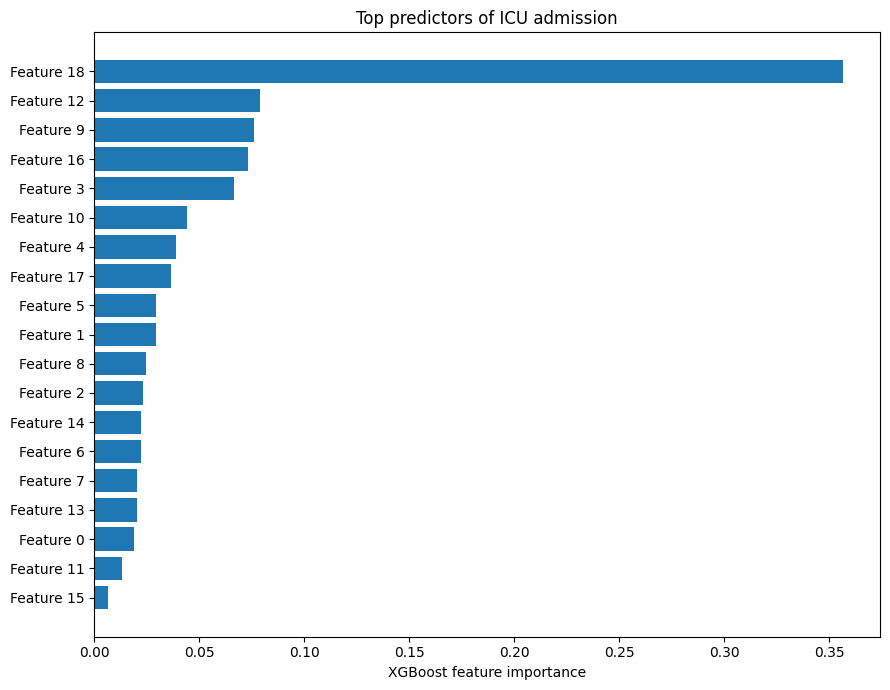

In [44]:
# ============================================================
# VISUALIZATION 7
# XGBOOST FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# Adjust variable if your classifier has another name

candidate_models = [
    "sw_model",
    "model_sw",
    "xgb_sw",
    "clf_sw",
    "xgb_model"
]


xgb_model_final = None


for name in candidate_models:

    if name in globals():

        xgb_model_final = globals()[name]

        print(
            "Using model:",
            name
        )

        break


if xgb_model_final is None:

    print(
        "Automatic model detection failed."
    )

    print(
        "Available variables containing "
        "'xgb' or 'model':"
    )

    print([
        k
        for k in globals().keys()
        if (
            "xgb" in k.lower()
            or "model" in k.lower()
        )
    ])

else:

    feature_names = None

    # Try known feature lists

    for candidate in [
        "SW_FEATURES",
        "FEATURE_COLS",
        "feature_cols",
        "X_FEATURES"
    ]:

        if candidate in globals():

            values = globals()[candidate]

            if (
                len(values)
                ==
                len(
                    xgb_model_final.feature_importances_
                )
            ):

                feature_names = list(values)

                break


    if feature_names is None:

        feature_names = [
            f"Feature {i}"
            for i in range(
                len(
                    xgb_model_final.feature_importances_
                )
            )
        ]


    importance_df = pd.DataFrame({
        "Feature": feature_names,

        "Importance":
            xgb_model_final.feature_importances_
    })


    importance_df = (
        importance_df
        .sort_values(
            "Importance",
            ascending=False
        )
        .head(20)
        .sort_values(
            "Importance"
        )
    )


    display(
        importance_df.sort_values(
            "Importance",
            ascending=False
        )
    )


    fig, ax = plt.subplots(
        figsize=(9, 7)
    )

    ax.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    ax.set_xlabel(
        "XGBoost feature importance"
    )

    ax.set_title(
        "Top predictors of ICU admission"
    )

    plt.tight_layout()
    plt.show()

In [47]:
# ============================================================
# FIX SHAP FEATURE-NAME + MATRIX DETECTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("SHAP FEATURE MATRIX DETECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Confirm model
# ------------------------------------------------------------

if "xgb_model_final" not in globals():
    raise NameError(
        "xgb_model_final is not defined."
    )

xgb_shap_model = xgb_model_final

expected_features = int(
    xgb_shap_model.n_features_in_
)

print(
    "\nModel:",
    type(xgb_shap_model).__name__
)

print(
    "Expected features:",
    expected_features
)


# ------------------------------------------------------------
# 2. Search for feature-name variables safely
# ------------------------------------------------------------

FEATURE_NAME_CANDIDATES = [
    "SW_FEATURES",
    "FEATURE_COLS",
    "feature_cols",
    "feature_names",
    "X_FEATURES",
    "STRUCT_WAVE_FEATURES",
    "ALL_FEATURES"
]

feature_names = None


print(
    "\nSearching for feature-name variables..."
)


for candidate in FEATURE_NAME_CANDIDATES:

    if candidate not in globals():
        continue

    obj = globals()[candidate]

    # IMPORTANT FIX:
    # skip variables that exist but are None
    if obj is None:

        print(
            f"Skipping {candidate}: None"
        )

        continue


    # Skip strings
    if isinstance(
        obj,
        str
    ):

        print(
            f"Skipping {candidate}: string"
        )

        continue


    # Try conversion safely
    try:

        values = list(obj)

    except TypeError:

        print(
            f"Skipping {candidate}: "
            f"not iterable ({type(obj).__name__})"
        )

        continue


    print(
        f"{candidate}: "
        f"{len(values)} entries"
    )


    if len(values) == expected_features:

        feature_names = values

        print(
            f"\n✓ Using feature names from: "
            f"{candidate}"
        )

        break


# ------------------------------------------------------------
# 3. Try feature names directly from XGBoost
# ------------------------------------------------------------

if feature_names is None:

    try:

        booster_names = (
            xgb_shap_model
            .get_booster()
            .feature_names
        )


        if (
            booster_names is not None
            and
            len(booster_names)
            == expected_features
        ):

            feature_names = list(
                booster_names
            )

            print(
                "\n✓ Using XGBoost booster "
                "feature names."
            )

    except Exception as e:

        print(
            "Could not retrieve booster names:",
            e
        )


# ------------------------------------------------------------
# 4. Search ALL notebook variables for a matching
#    2-D test matrix with exactly 19 features
# ------------------------------------------------------------

print(
    "\nSearching notebook for "
    f"2-D matrices with {expected_features} features..."
)


matrix_candidates = []


for name, obj in list(
    globals().items()
):

    if obj is None:
        continue


    # Avoid huge/non-data objects
    if not (
        isinstance(
            obj,
            (
                np.ndarray,
                pd.DataFrame
            )
        )
    ):
        continue


    try:

        shape = obj.shape

    except Exception:
        continue


    if len(shape) != 2:
        continue


    if shape[1] == expected_features:

        matrix_candidates.append(
            (
                name,
                shape,
                type(obj).__name__
            )
        )


print(
    "\nMatrices with exactly "
    f"{expected_features} columns:"
)


for item in matrix_candidates:

    print(
        f"  {item[0]:30s} "
        f"shape={item[1]} "
        f"type={item[2]}"
    )


# ------------------------------------------------------------
# 5. Prefer a matrix whose row count equals test_df
# ------------------------------------------------------------

X_shap = None
X_shap_name = None


if "test_df" in globals():

    test_rows = len(
        test_df
    )

    print(
        "\nExpected test rows:",
        test_rows
    )


    preferred_names = [
        "Xte_sw",
        "X_test_sw",
        "X_sw_test",
        "Xtest_sw",
        "Xte",
        "X_test",
        "X_te",
        "Xtest"
    ]


    # First: preferred names
    for preferred in preferred_names:

        for (
            name,
            shape,
            object_type
        ) in matrix_candidates:

            if (
                name == preferred
                and
                shape[0] == test_rows
            ):

                X_shap = globals()[
                    name
                ]

                X_shap_name = name

                break

        if X_shap is not None:
            break


    # Second: any 19-feature matrix
    # with exactly the test row count

    if X_shap is None:

        matching_test_matrices = [
            item
            for item
            in matrix_candidates
            if item[1][0] == test_rows
        ]


        if len(
            matching_test_matrices
        ) == 1:

            name = (
                matching_test_matrices[
                    0
                ][0]
            )

            X_shap = globals()[
                name
            ]

            X_shap_name = name


        elif len(
            matching_test_matrices
        ) > 1:

            print(
                "\nMultiple possible test "
                "matrices found:"
            )

            for item in matching_test_matrices:

                print(
                    " ",
                    item
                )


# ------------------------------------------------------------
# 6. If matrix found, recover column names
# ------------------------------------------------------------

if X_shap is not None:

    print(
        "\n✓ Test matrix found:"
    )

    print(
        "Variable:",
        X_shap_name
    )

    print(
        "Shape:",
        X_shap.shape
    )


    # DataFrame already contains ideal names

    if isinstance(
        X_shap,
        pd.DataFrame
    ):

        if len(
            X_shap.columns
        ) == expected_features:

            feature_names = list(
                X_shap.columns
            )

            print(
                "✓ Feature names taken "
                "directly from DataFrame."
            )


# ------------------------------------------------------------
# 7. If names still unavailable, inspect known
#    structured/waveform lists
# ------------------------------------------------------------

if feature_names is None:

    print(
        "\nNo exact 19-element feature-name "
        "list was found."
    )


    print(
        "\nPotential structured features "
        "available in test_df:"
    )


    structured_candidates = [
        "Age",
        "Gender",
        "Means_of_arrival",
        "Triage_Temp",
        "Triage_HR",
        "Triage_RR",
        "Triage_SpO2",
        "Triage_SBP",
        "Triage_DBP"
    ]


    available_structured = [
        c
        for c in structured_candidates
        if (
            "test_df" in globals()
            and
            c in test_df.columns
        )
    ]


    print(
        available_structured
    )


    if (
        "WAVE_COLS" in globals()
        and
        WAVE_COLS is not None
    ):

        print(
            "\nWAVE_COLS:"
        )

        print(
            list(WAVE_COLS)
        )


# ------------------------------------------------------------
# 8. Final diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DETECTION RESULT")
print("=" * 70)


print(
    "Expected features:",
    expected_features
)


print(
    "Feature names found:",
    feature_names is not None
)


if feature_names is not None:

    print(
        "Number of names:",
        len(feature_names)
    )

    print(
        "\nFeature names:"
    )

    for i, name in enumerate(
        feature_names,
        start=1
    ):

        print(
            f"{i:02d}. {name}"
        )


print(
    "\nTest feature matrix found:",
    X_shap is not None
)


if X_shap is not None:

    print(
        "Matrix:",
        X_shap_name
    )

    print(
        "Shape:",
        X_shap.shape
    )


# ------------------------------------------------------------
# 9. Do NOT create fake names yet
# ------------------------------------------------------------

if X_shap is None:

    print(
        "\n⚠ No exact test matrix was "
        "identified automatically."
    )

    print(
        "Use the matrix-candidate output above "
        "to identify the correct test matrix."
    )

else:

    print(
        "\n✓ Exact 19-feature matrix located."
    )

SHAP FEATURE MATRIX DETECTION

Model: XGBClassifier
Expected features: 19

Searching for feature-name variables...
Skipping feature_names: None

Searching notebook for 2-D matrices with 19 features...

Matrices with exactly 19 columns:
  Xsw_val                        shape=(12062, 19) type=ndarray
  Xsw_test                       shape=(11666, 19) type=ndarray

Expected test rows: 11666

✓ Test matrix found:
Variable: Xsw_test
Shape: (11666, 19)

No exact 19-element feature-name list was found.

Potential structured features available in test_df:
['Age', 'Gender', 'Means_of_arrival', 'Triage_Temp', 'Triage_HR', 'Triage_RR', 'Triage_SpO2', 'Triage_SBP', 'Triage_DBP']

WAVE_COLS:
['total_segments', 'total_duration', 'n_waveform_types', 'II', 'Pleth', 'Resp']

DETECTION RESULT
Expected features: 19
Feature names found: False

Test feature matrix found: True
Matrix: Xsw_test
Shape: (11666, 19)

✓ Exact 19-feature matrix located.


SHAP input: Xsw_test
SHAP sample shape: (2000, 19)
SHAP values: (2000, 19)

⚠ Original feature names unavailable.


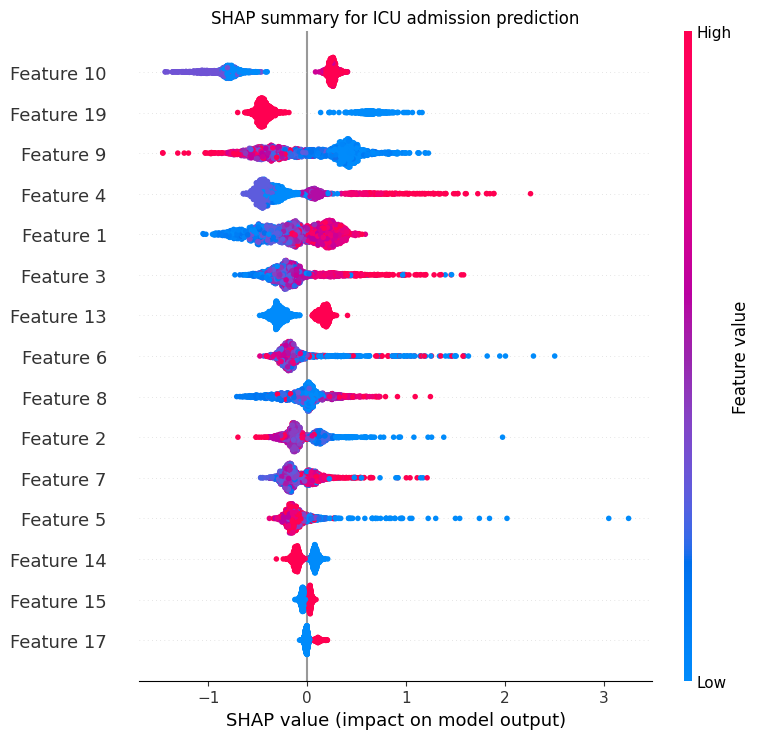

,Feature,Mean |SHAP|
0,Feature 10,0.567758
1,Feature 19,0.476693
2,Feature 9,0.383863
3,Feature 4,0.374818
4,Feature 1,0.294992
5,Feature 3,0.258516
6,Feature 13,0.236433
7,Feature 6,0.220798
8,Feature 8,0.162459
9,Feature 2,0.154450


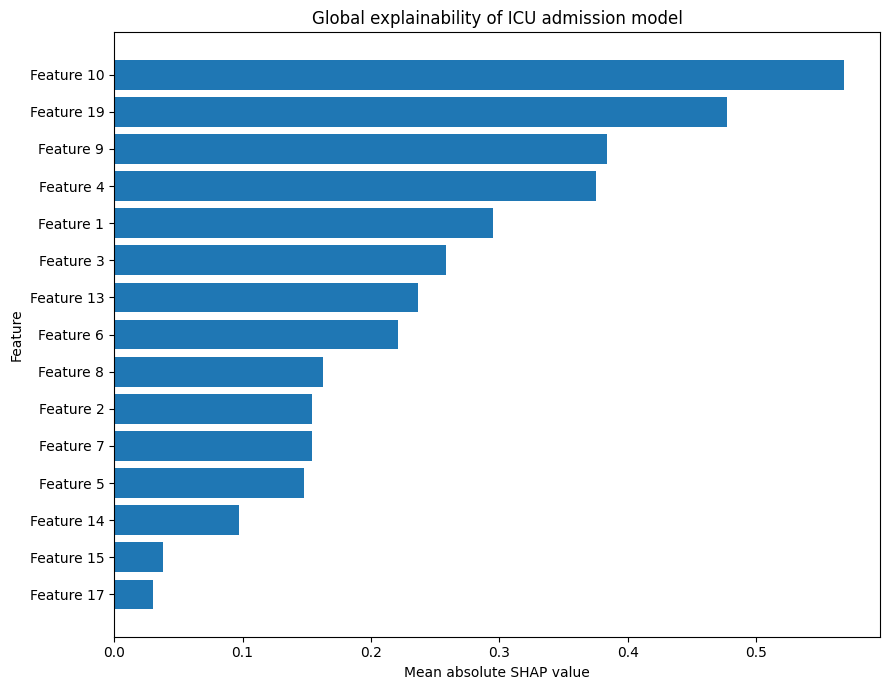

In [48]:
# ============================================================
# RUN SHAP USING EXACT XGBOOST INPUT MATRIX
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Sample test encounters
# ------------------------------------------------------------

rng = np.random.default_rng(
    SEED
)


SHAP_SAMPLE_SIZE = min(
    2000,
    len(X_shap)
)


sample_idx = rng.choice(
    len(X_shap),
    size=SHAP_SAMPLE_SIZE,
    replace=False
)


if isinstance(
    X_shap,
    pd.DataFrame
):

    X_shap_sample = (
        X_shap
        .iloc[sample_idx]
        .copy()
    )

else:

    X_shap_sample = np.asarray(
        X_shap
    )[sample_idx]


print(
    "SHAP input:",
    X_shap_name
)

print(
    "SHAP sample shape:",
    X_shap_sample.shape
)


assert (
    X_shap_sample.shape[1]
    ==
    xgb_shap_model.n_features_in_
)


# ------------------------------------------------------------
# Explain model
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_shap_model
)


shap_values = explainer.shap_values(
    X_shap_sample
)


if isinstance(
    shap_values,
    list
):

    shap_values = (
        shap_values[-1]
    )


shap_values = np.asarray(
    shap_values
)


print(
    "SHAP values:",
    shap_values.shape
)


# ------------------------------------------------------------
# Feature names
# ------------------------------------------------------------

if feature_names is None:

    # Only use generic names if the original
    # training names genuinely cannot be recovered.

    feature_names_plot = [
        f"Feature {i + 1}"
        for i in range(
            expected_features
        )
    ]

    print(
        "\n⚠ Original feature names unavailable."
    )

else:

    feature_names_plot = (
        feature_names
    )


# ------------------------------------------------------------
# SHAP beeswarm
# ------------------------------------------------------------

shap.summary_plot(
    shap_values,
    X_shap_sample,
    feature_names=feature_names_plot,
    max_display=15,
    show=False
)


plt.title(
    "SHAP summary for ICU admission prediction"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Mean absolute SHAP
# ------------------------------------------------------------

mean_shap = (
    np.abs(
        shap_values
    )
    .mean(axis=0)
)


shap_df = pd.DataFrame({
    "Feature":
        feature_names_plot,

    "Mean |SHAP|":
        mean_shap
})


shap_df = (
    shap_df
    .sort_values(
        "Mean |SHAP|",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    shap_df
)


# ------------------------------------------------------------
# SHAP importance bar plot
# ------------------------------------------------------------

top = (
    shap_df
    .head(15)
    .sort_values(
        "Mean |SHAP|"
    )
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


ax.barh(
    top["Feature"],
    top["Mean |SHAP|"]
)


ax.set_xlabel(
    "Mean absolute SHAP value"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Global explainability of ICU admission model"
)


plt.tight_layout()

plt.show()

Explaining SHAP sample encounter: 0


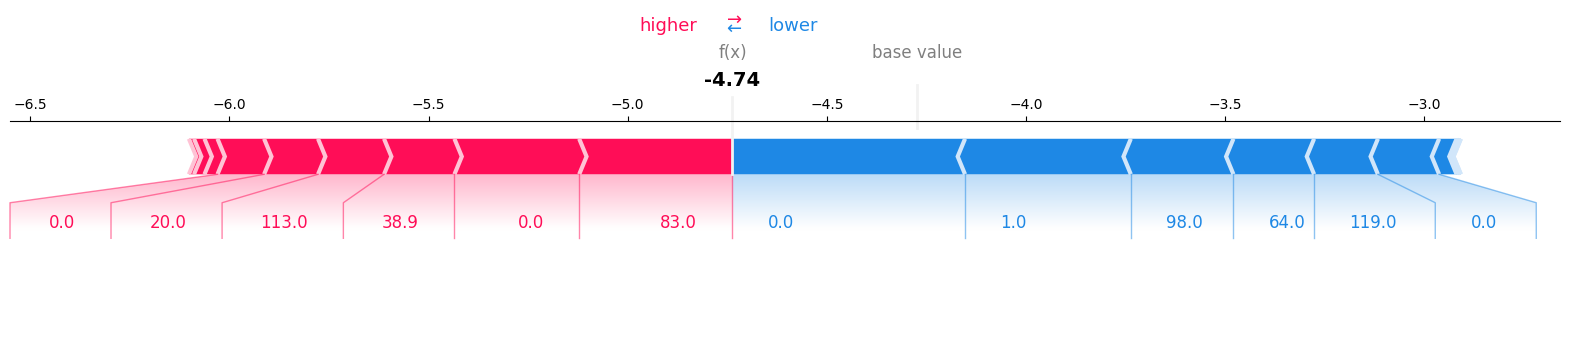

<Figure size 640x480 with 0 Axes>

In [51]:
# ============================================================
# VISUALIZATION 10
# LOCAL PATIENT EXPLANATION
# ============================================================

import shap


patient_index = 0


print(
    "Explaining SHAP sample encounter:",
    patient_index
)


if isinstance(
    X_shap_sample,
    pd.DataFrame
):

    patient_features = (
        X_shap_sample.iloc[
            patient_index
        ]
    )

else:

    patient_features = (
        X_shap_sample[
            patient_index
        ]
    )


expected_value = (
    explainer.expected_value
)


if isinstance(
    expected_value,
    (list, np.ndarray)
):

    expected_value = np.asarray(
        expected_value
    ).reshape(-1)[0]


shap.force_plot(
    expected_value,
    shap_values[
        patient_index
    ],
    patient_features,
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

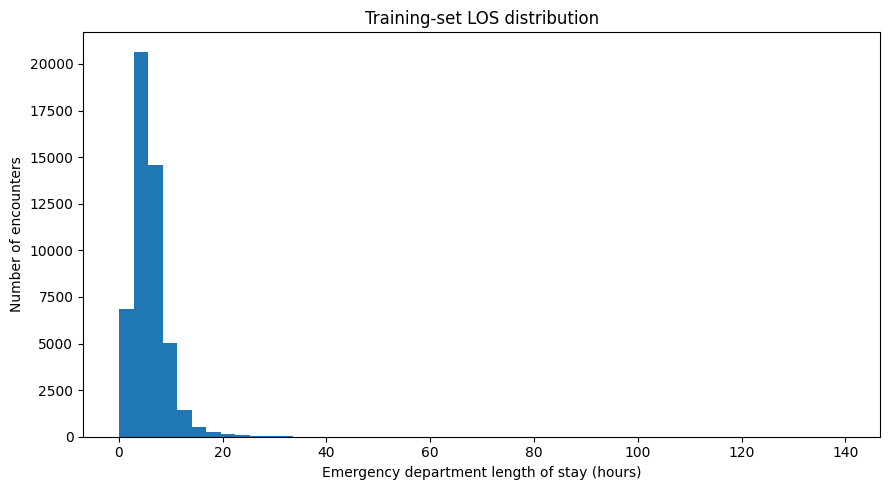

count    49725.000000
mean         5.928841
std          3.577126
min          0.130000
25%          3.750000
50%          5.370000
75%          7.330000
90%          9.580000
95%         11.400000
99%         18.250000
max        139.679993
dtype: float64


In [52]:
# ============================================================
# VISUALIZATION 11
# LOS DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd


los_plot_df = pd.DataFrame({
    "LOS_hours": y_tr
})


fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    los_plot_df["LOS_hours"],
    bins=50
)

ax.set_xlabel(
    "Emergency department length of stay (hours)"
)

ax.set_ylabel(
    "Number of encounters"
)

ax.set_title(
    "Training-set LOS distribution"
)

plt.tight_layout()
plt.show()


print(
    pd.Series(
        y_tr
    ).describe(
        percentiles=[
            0.25,
            0.5,
            0.75,
            0.9,
            0.95,
            0.99
        ]
    )
)

,Vital,Observed (%),Missing (%)
0,HR,27.780001,72.220001
1,RR,24.730000,75.269997
2,SpO2,34.070000,65.930000
3,SBP,5.260000,94.739998
4,DBP,5.200000,94.800003
5,MAP,5.200000,94.800003
6,Temp,1.680000,98.320000


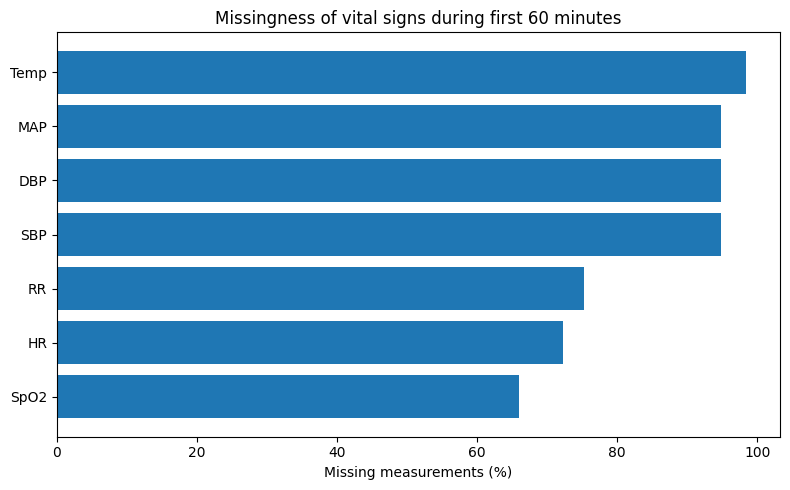

In [54]:
# ============================================================
# VISUALIZATION 12
# VITAL-SIGN MISSINGNESS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


observed_rate = (
    M_tr.mean(
        axis=(0, 1)
    )
)


missing_rate = (
    1.0
    -
    observed_rate
)


missing_df = pd.DataFrame({
    "Vital": VITALS,
    "Observed (%)":
        observed_rate * 100,
    "Missing (%)":
        missing_rate * 100
})


display(
    missing_df.round(2)
)


plot_df = (
    missing_df
    .sort_values(
        "Missing (%)"
    )
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.barh(
    plot_df["Vital"],
    plot_df["Missing (%)"]
)

ax.set_xlabel(
    "Missing measurements (%)"
)

ax.set_title(
    "Missingness of vital signs during first 60 minutes"
)

plt.tight_layout()
plt.show()

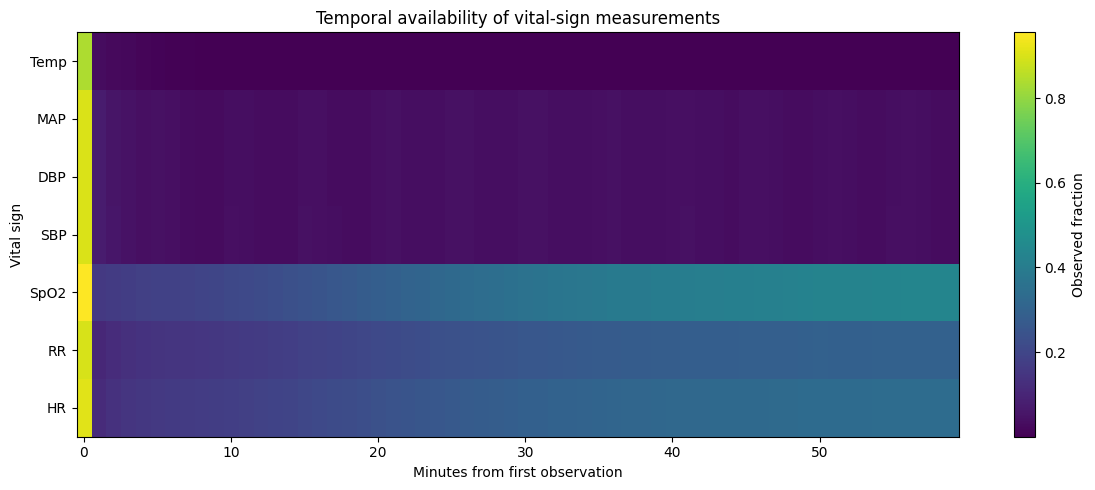

In [55]:
# ============================================================
# VISUALIZATION 13
# TEMPORAL MISSINGNESS HEATMAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# Observation rate:
# minute × vital

observation_by_time = (
    M_tr.mean(axis=0)
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)


image = ax.imshow(
    observation_by_time.T,
    aspect="auto",
    origin="lower"
)


ax.set_xlabel(
    "Minutes from first observation"
)

ax.set_ylabel(
    "Vital sign"
)

ax.set_yticks(
    np.arange(
        len(VITALS)
    )
)

ax.set_yticklabels(
    VITALS
)

ax.set_title(
    "Temporal availability of vital-sign measurements"
)


cbar = plt.colorbar(
    image,
    ax=ax
)

cbar.set_label(
    "Observed fraction"
)


plt.tight_layout()
plt.show()

CSN: 99354408
LOS: 9.53 hours


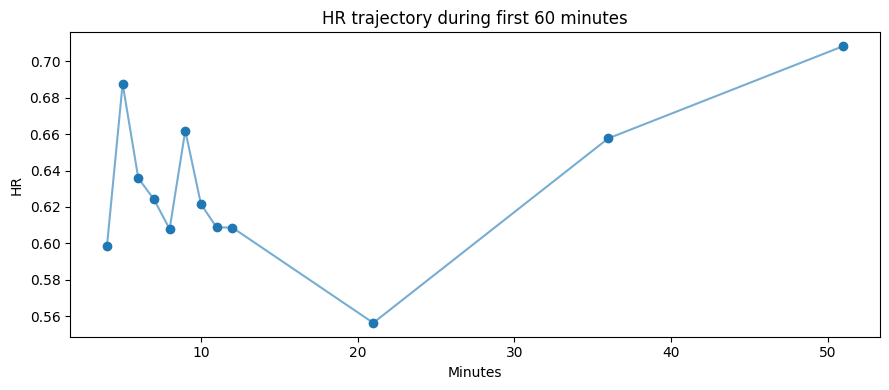

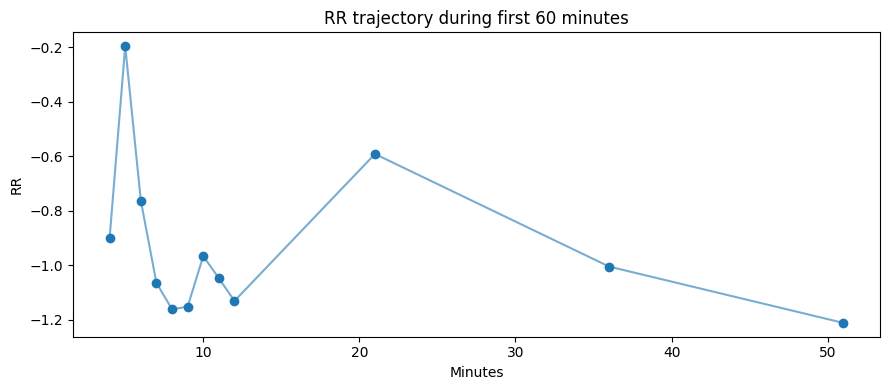

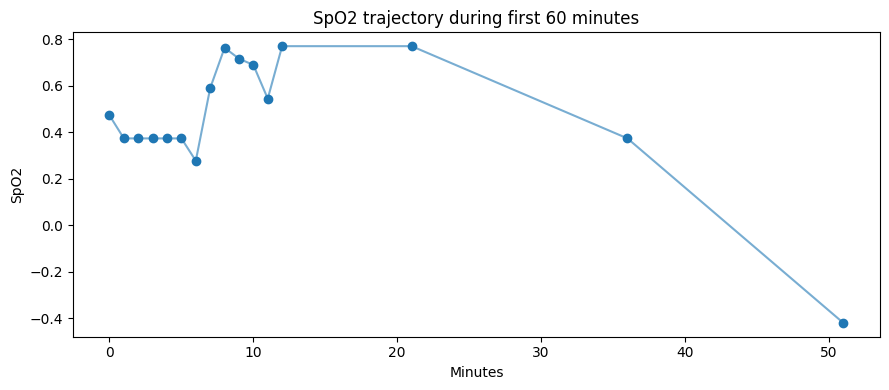

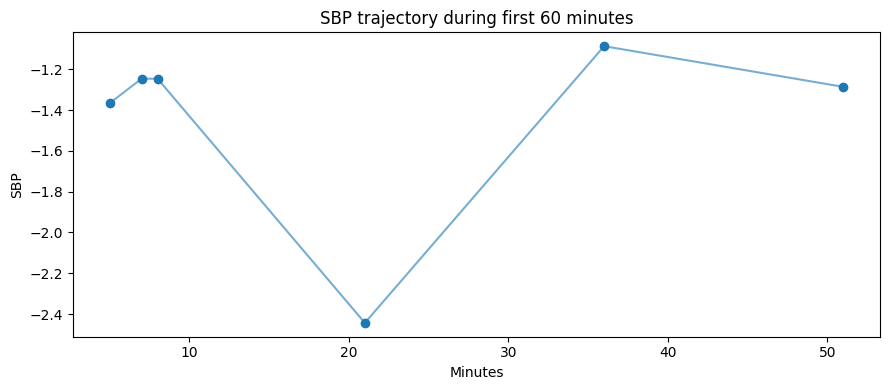

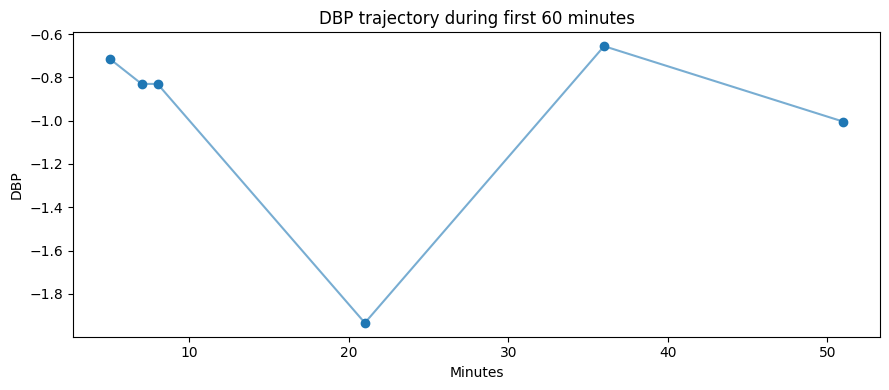

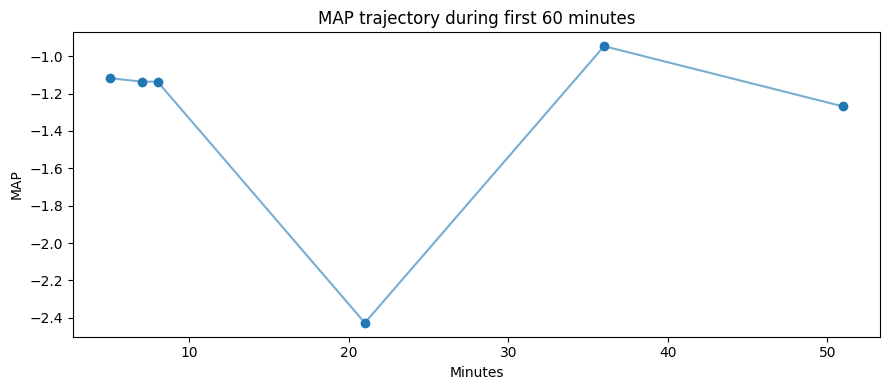

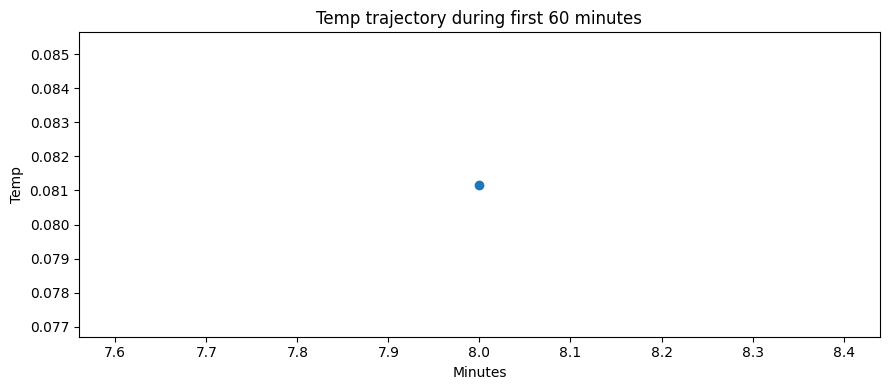

In [57]:
# ============================================================
# VISUALIZATION 14
# EXAMPLE TEMPORAL TRAJECTORY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


patient_idx = 0

minutes = np.arange(T)


print(
    "CSN:",
    csn_tr[patient_idx]
)

print(
    "LOS:",
    y_tr[patient_idx],
    "hours"
)


for vital_index, vital in enumerate(VITALS):

    values = Xt_tr[
        patient_idx,
        :,
        vital_index
    ]

    observed = (
        M_tr[
            patient_idx,
            :,
            vital_index
        ]
        ==
        1
    )


    if observed.sum() == 0:
        continue


    fig, ax = plt.subplots(
        figsize=(9, 4)
    )

    ax.scatter(
        minutes[observed],
        values[observed]
    )

    ax.plot(
        minutes[observed],
        values[observed],
        alpha=0.6
    )

    ax.set_xlabel(
        "Minutes"
    )

    ax.set_ylabel(
        vital
    )

    ax.set_title(
        f"{vital} trajectory during first 60 minutes"
    )

    plt.tight_layout()
    plt.show()

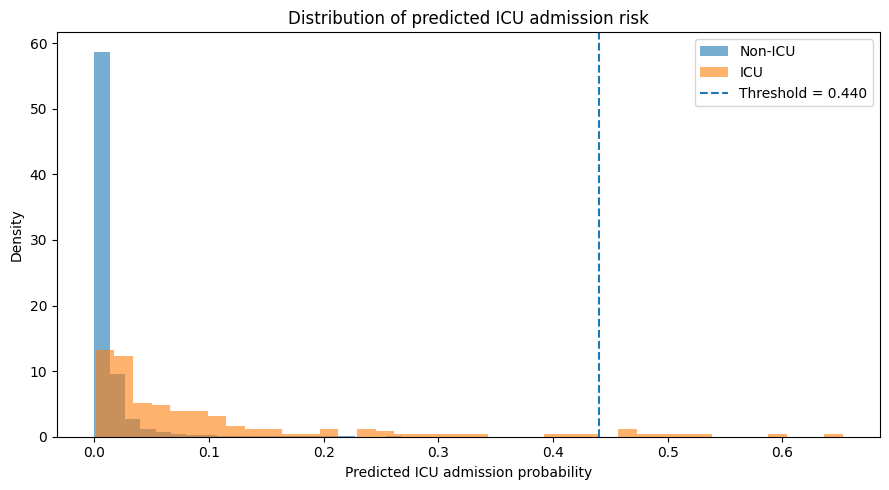

In [61]:
# ============================================================
# VISUALIZATION 18
# PREDICTED RISK DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt


non_icu_probs = final_probs[
    y_true == 0
]

icu_probs = final_probs[
    y_true == 1
]


fig, ax = plt.subplots(
    figsize=(9, 5)
)


ax.hist(
    non_icu_probs,
    bins=40,
    alpha=0.6,
    label="Non-ICU",
    density=True
)


ax.hist(
    icu_probs,
    bins=40,
    alpha=0.6,
    label="ICU",
    density=True
)


ax.axvline(
    THRESHOLD,
    linestyle="--",
    label=f"Threshold = {THRESHOLD:.3f}"
)


ax.set_xlabel(
    "Predicted ICU admission probability"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "Distribution of predicted ICU admission risk"
)

ax.legend()


plt.tight_layout()
plt.show()

In [63]:
# ============================================================
# PUBLICATION FIGURE SETTINGS
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

FIG_DIR = Path(
    "/kaggle/working/medfusionnet_figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def save_figure(
    filename
):

    path = FIG_DIR / filename

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        "Saved:",
        path
    )


print(
    "Figure directory:",
    FIG_DIR
)

Figure directory: /kaggle/working/medfusionnet_figures


In [66]:
# ============================================================
# GRU + GRU-D ONLY — DIAGNOSTIC
# ============================================================

import numpy as np

print("=" * 65)
print("GRU / GRU-D STATUS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Required temporal tensors
# ------------------------------------------------------------

required = [
    "Xt_tr", "M_tr", "D_tr", "y_tr",
    "Xt_va", "M_va", "D_va", "y_va",
    "Xt_te", "M_te", "D_te", "y_te"
]

print("\nTEMPORAL DATA")
print("-" * 65)

for name in required:

    if name not in globals():

        print(f"{name:10s} : MISSING")

    else:

        obj = globals()[name]

        try:
            print(
                f"{name:10s} : {obj.shape}"
            )

        except:
            print(
                f"{name:10s} : EXISTS"
            )


# ------------------------------------------------------------
# 2. Vital signs
# ------------------------------------------------------------

print("\nVITALS")
print("-" * 65)

if "VITALS" in globals():

    print(VITALS)

else:

    print("VITALS is MISSING")


# ------------------------------------------------------------
# 3. Find GRU / GRU-D models
# ------------------------------------------------------------

print("\nGRU / GRU-D MODEL VARIABLES")
print("-" * 65)

found_models = False

try:

    import torch

    for name, obj in globals().copy().items():

        if isinstance(
            obj,
            torch.nn.Module
        ):

            if "gru" in (
                name
                +
                type(obj).__name__
            ).lower():

                found_models = True

                params = sum(
                    p.numel()
                    for p in obj.parameters()
                )

                print(
                    f"{name:25s} "
                    f"{type(obj).__name__:20s} "
                    f"parameters={params:,}"
                )

except Exception as e:

    print(
        "Model scan error:",
        e
    )


if not found_models:

    print(
        "NO TRAINED GRU/GRU-D MODEL FOUND"
    )


# ------------------------------------------------------------
# 4. Find GRU prediction variables
# ------------------------------------------------------------

print("\nGRU / GRU-D PREDICTION VARIABLES")
print("-" * 65)

found_predictions = False

for name, obj in globals().copy().items():

    lower = name.lower()

    if (
        "pred" in lower
        and
        "gru" in lower
    ):

        found_predictions = True

        try:

            arr = np.asarray(obj)

            print(
                f"{name:30s} "
                f"shape={arr.shape} "
                f"finite={np.isfinite(arr).all()}"
            )

        except Exception:

            print(
                f"{name:30s} "
                f"type={type(obj).__name__}"
            )


if not found_predictions:

    print(
        "NO GRU/GRU-D PREDICTIONS FOUND"
    )


# ------------------------------------------------------------
# 5. Look for arrays matching test-set size
# ------------------------------------------------------------

print("\nPOSSIBLE TEST PREDICTIONS")
print("-" * 65)

if "y_te" in globals():

    n_test = len(y_te)

    print(
        "Expected test size:",
        n_test
    )

    for name, obj in globals().copy().items():

        if not isinstance(
            obj,
            np.ndarray
        ):
            continue

        try:

            arr = np.asarray(obj)

            if (
                arr.ndim <= 2
                and
                arr.size == n_test
            ):

                print(
                    f"{name:30s} "
                    f"shape={arr.shape}"
                )

        except:
            pass

else:

    print(
        "y_te is MISSING"
    )


# ------------------------------------------------------------
# 6. Integrity check
# ------------------------------------------------------------

print("\nINTEGRITY")
print("-" * 65)

for prefix in [
    ("TRAIN", "Xt_tr", "M_tr", "D_tr", "y_tr"),
    ("VAL",   "Xt_va", "M_va", "D_va", "y_va"),
    ("TEST",  "Xt_te", "M_te", "D_te", "y_te")
]:

    label, xn, mn, dn, yn = prefix

    if all(
        x in globals()
        for x in [xn, mn, dn, yn]
    ):

        X = globals()[xn]
        M = globals()[mn]
        D = globals()[dn]
        y = globals()[yn]

        aligned = (
            len(X)
            ==
            len(M)
            ==
            len(D)
            ==
            len(y)
        )

        print(
            f"{label:6s}: "
            f"aligned={aligned}, "
            f"N={len(y)}"
        )


print("\n" + "=" * 65)
print("DONE")
print("=" * 65)

GRU / GRU-D STATUS

TEMPORAL DATA
-----------------------------------------------------------------
Xt_tr      : (49725, 60, 7)
M_tr       : (49725, 60, 7)
D_tr       : (49725, 60, 7)
y_tr       : (49725,)
Xt_va      : (6350, 60, 7)
M_va       : (6350, 60, 7)
D_va       : (6350, 60, 7)
y_va       : (6350,)
Xt_te      : (6068, 60, 7)
M_te       : (6068, 60, 7)
D_te       : (6068, 60, 7)
y_te       : (6068,)

VITALS
-----------------------------------------------------------------
['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']

GRU / GRU-D MODEL VARIABLES
-----------------------------------------------------------------
gru                       GRUBaseline          parameters=14,081
grud                      GRUD                 parameters=15,993

GRU / GRU-D PREDICTION VARIABLES
-----------------------------------------------------------------
gru_pred                       type=NoneType
grud_pred                      type=NoneType
pred_gru                       type=NoneType
pred_g

MEDFUSIONNET — GRU + GRU-D
Device: cuda

DATA SHAPES
---------------------------------------------------------------------------
TRAIN : (49725, 60, 7) (49725, 60, 7) (49725, 60, 7) (49725,)
VAL   : (6350, 60, 7) (6350, 60, 7) (6350, 60, 7) (6350,)
TEST  : (6068, 60, 7) (6068, 60, 7) (6068, 60, 7) (6068,)

Sequence length : 60
Number features: 7
Features: ['HR', 'RR', 'SpO2', 'SBP', 'DBP', 'MAP', 'Temp']
TRAIN non-finite targets: 0
VAL non-finite targets: 0
TEST non-finite targets: 0

Normalization complete.
Training X finite: True
Training D finite: True

GRU parameters: 14081
GRU-D parameters: 15993

TRAINING GRU
GRU    | Epoch 01 | Train RMSE=4.2334 | Val RMSE=3.6695
GRU    | Epoch 02 | Train RMSE=3.5960 | Val RMSE=3.6523
GRU    | Epoch 03 | Train RMSE=3.5695 | Val RMSE=3.6226
GRU    | Epoch 04 | Train RMSE=3.5564 | Val RMSE=3.6206
GRU    | Epoch 05 | Train RMSE=3.5560 | Val RMSE=3.6219
GRU    | Epoch 06 | Train RMSE=3.5519 | Val RMSE=3.6228
GRU    | Epoch 07 | Train RMSE=3.5484 | V

,Model,RMSE (h),MAE (h),Median AE (h),R²
0,GRU,3.9013,2.3546,1.8617,0.0199
1,GRU-D,3.9007,2.3381,1.8263,0.0202


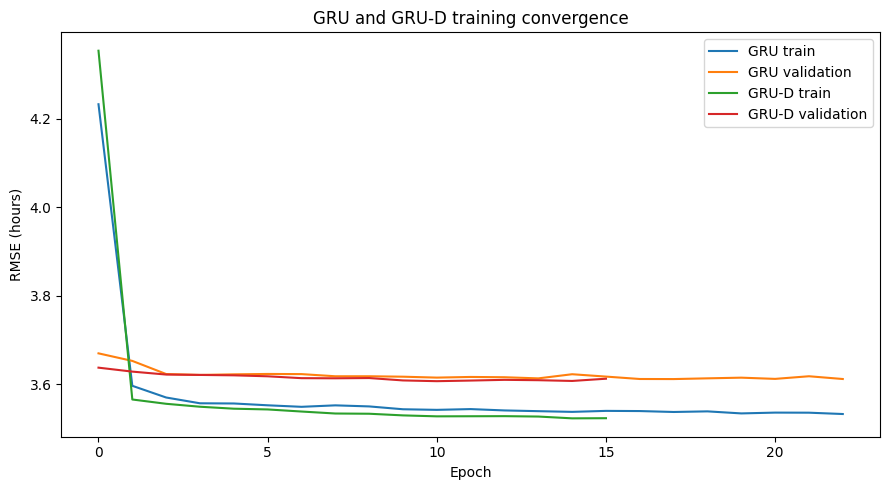

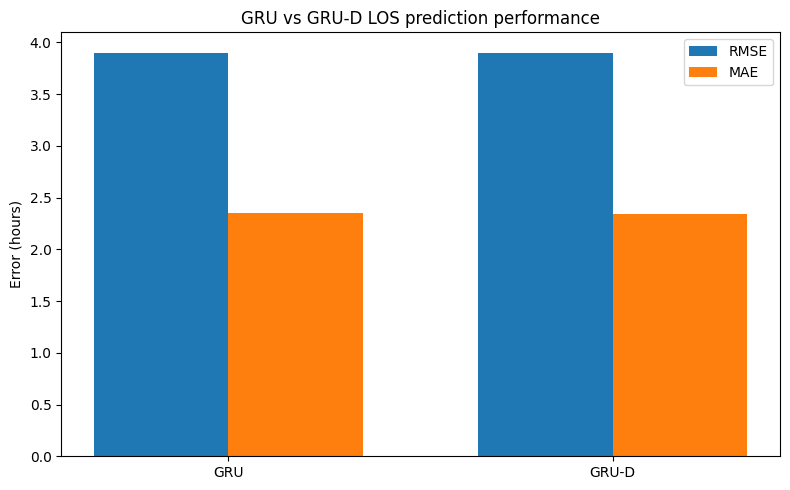

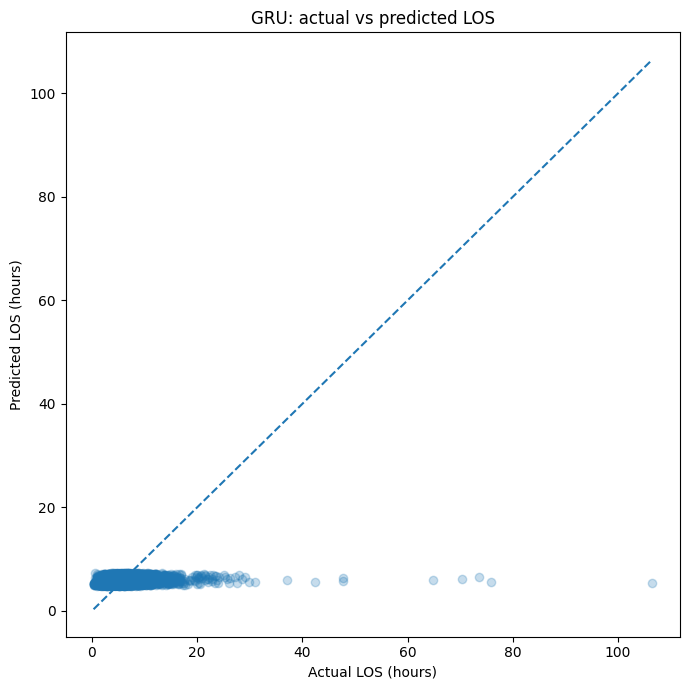

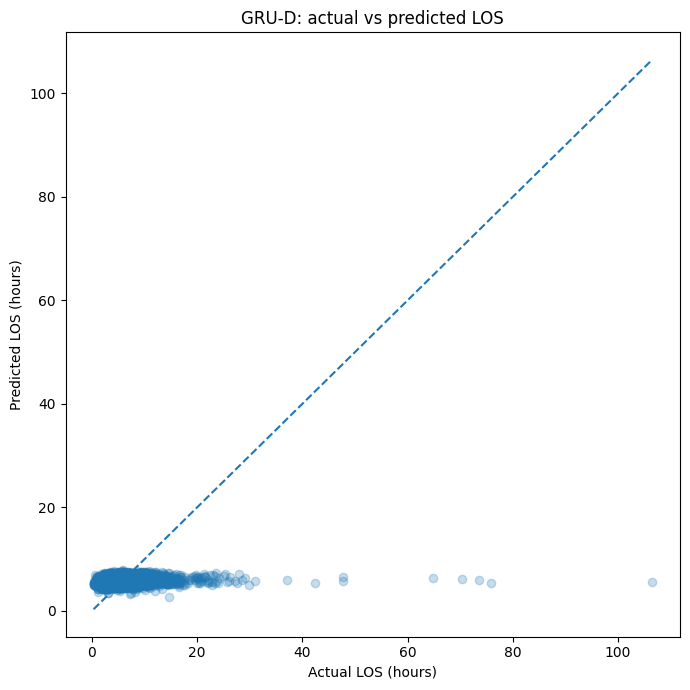

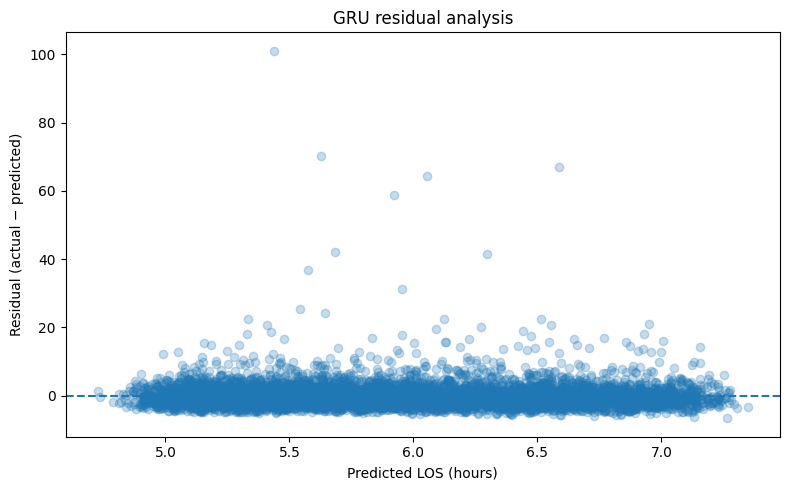

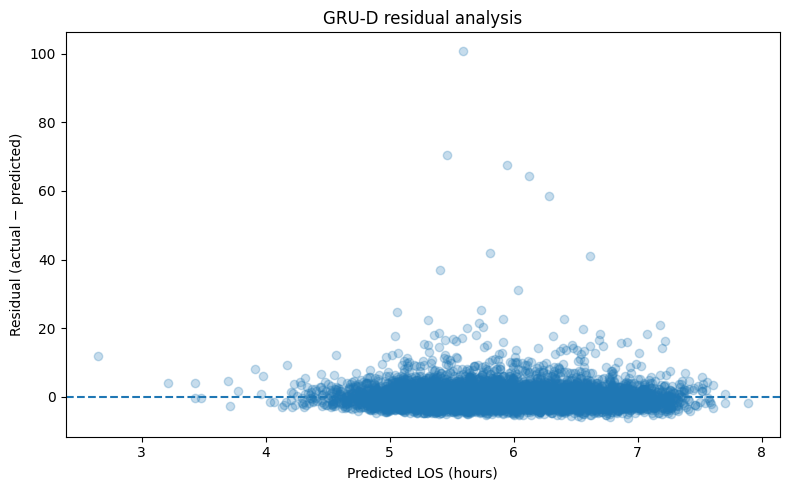

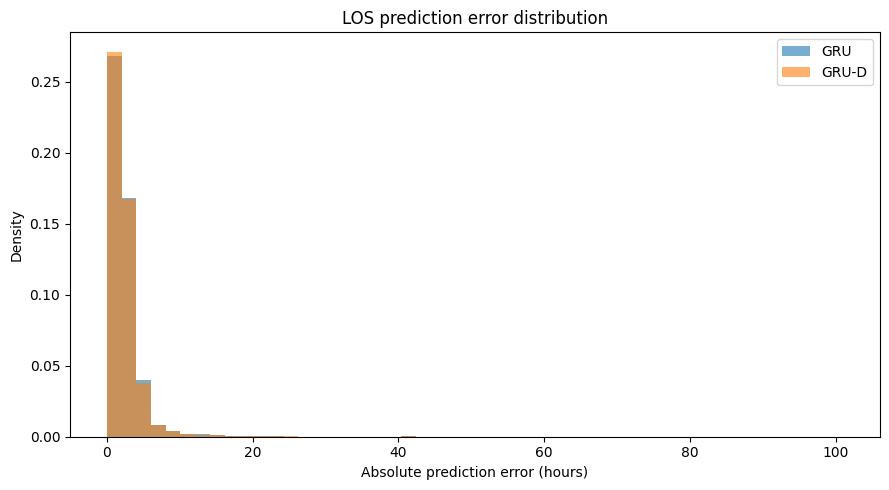

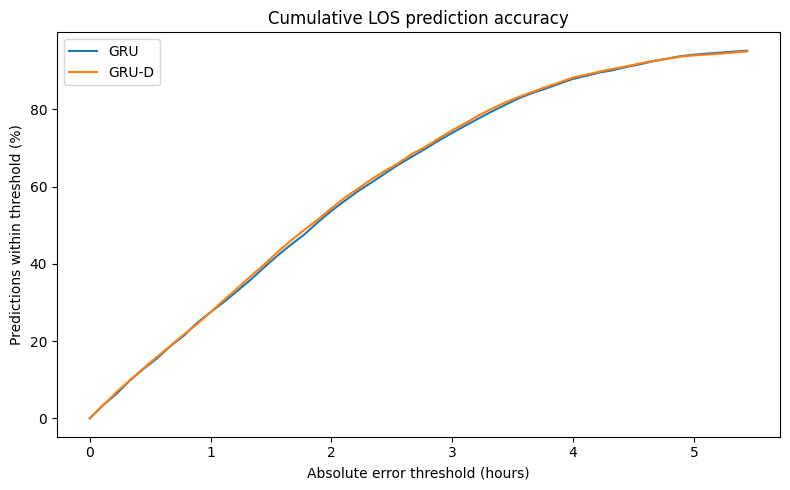


MISSINGNESS


,Vital,Observed (%),Missing (%)
0,HR,27.780001,72.220001
1,RR,24.730000,75.269997
2,SpO2,34.070000,65.930000
3,SBP,5.260000,94.739998
4,DBP,5.200000,94.800003
5,MAP,5.200000,94.800003
6,Temp,1.680000,98.320000


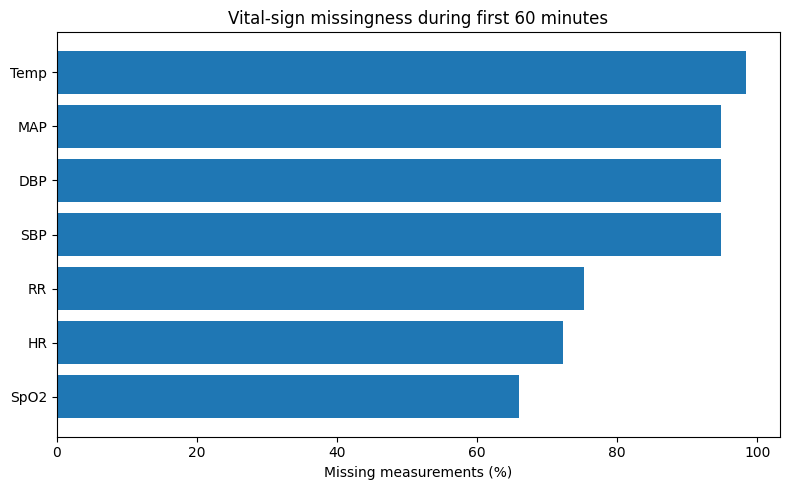

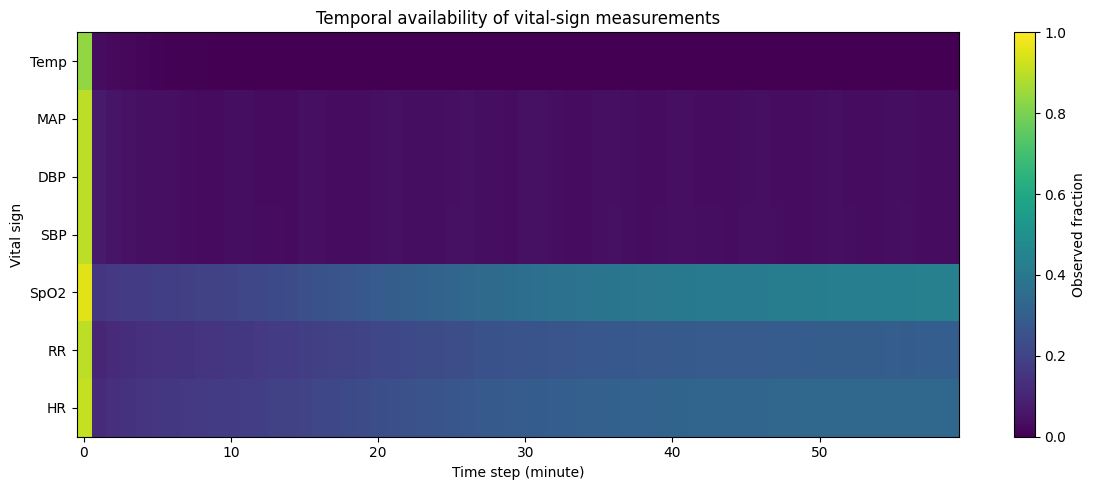


TIME-GAP STATISTICS


,Vital,Mean gap,Median gap,95th percentile
0,HR,18.174000,13.0,53.0
1,RR,19.393999,15.0,54.0
2,SpO2,16.181999,9.0,52.0
3,SBP,20.737000,16.0,53.0
4,DBP,20.798000,16.0,53.0
5,MAP,20.799000,16.0,53.0
6,Temp,28.672001,28.0,56.0


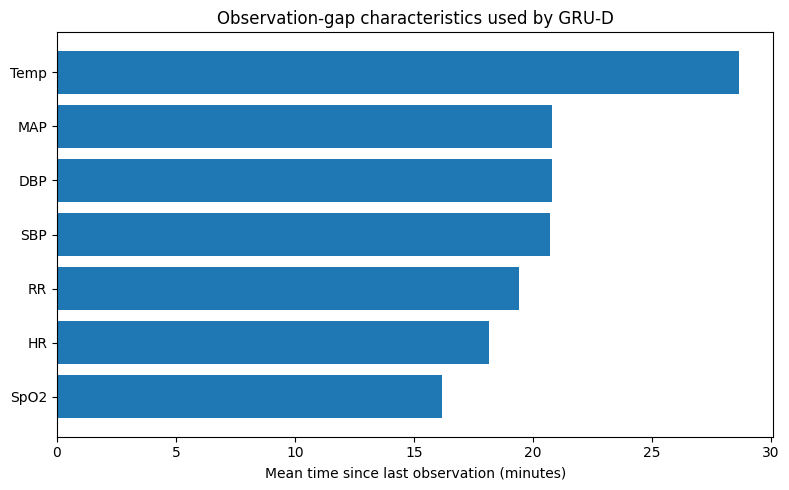

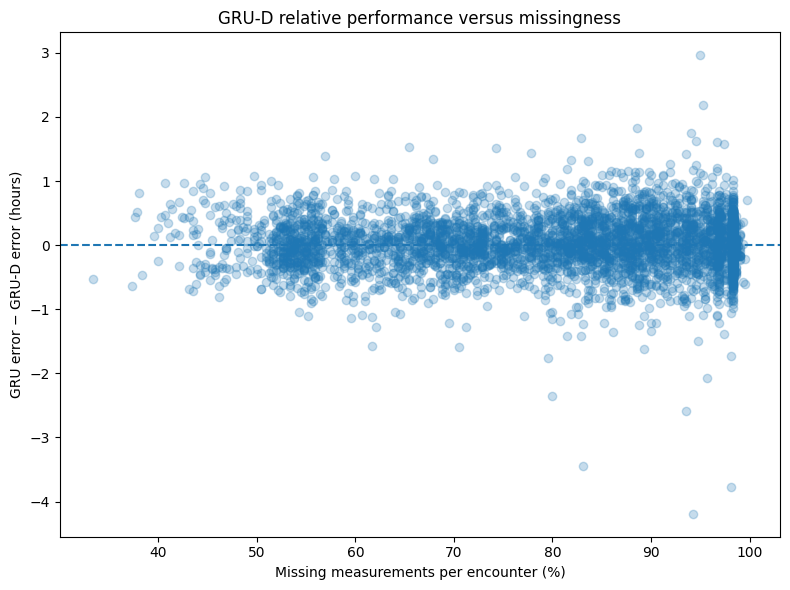

Missingness / GRU-D improvement correlation: -0.0162

PERFORMANCE BY MISSINGNESS


,Group,GRU_MAE,GRUD_MAE,N
0,Q1 lowest,2.2422,2.2298,1528
1,Q2,2.3084,2.2524,1516
2,Q3,2.4336,2.4343,2956
3,Q4 highest,2.4709,2.5036,68


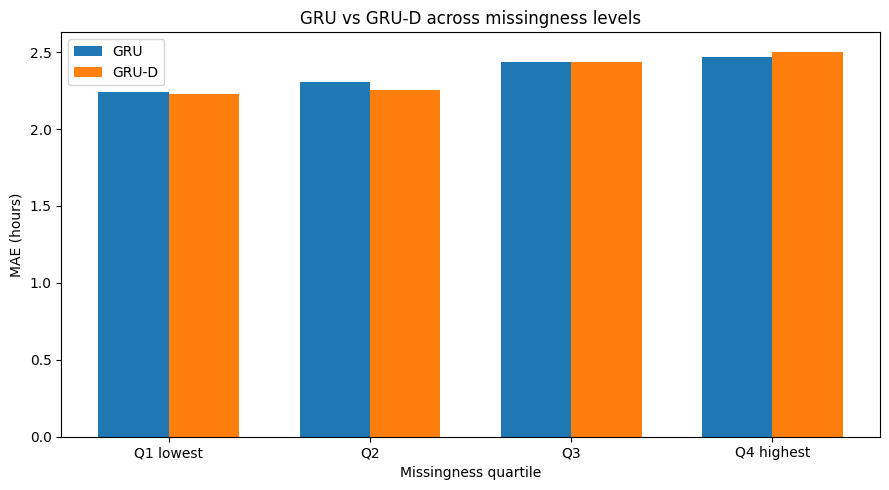


PERFORMANCE BY LOS RANGE


,LOS group,GRU_MAE,GRUD_MAE,N
0,≤4 h,2.9491,2.8547,1756
1,4–8 h,1.0364,1.0354,3146
2,8–12 h,3.3205,3.3714,928
3,12–24 h,9.1693,9.2658,216
4,>24 h,35.7481,35.7831,22


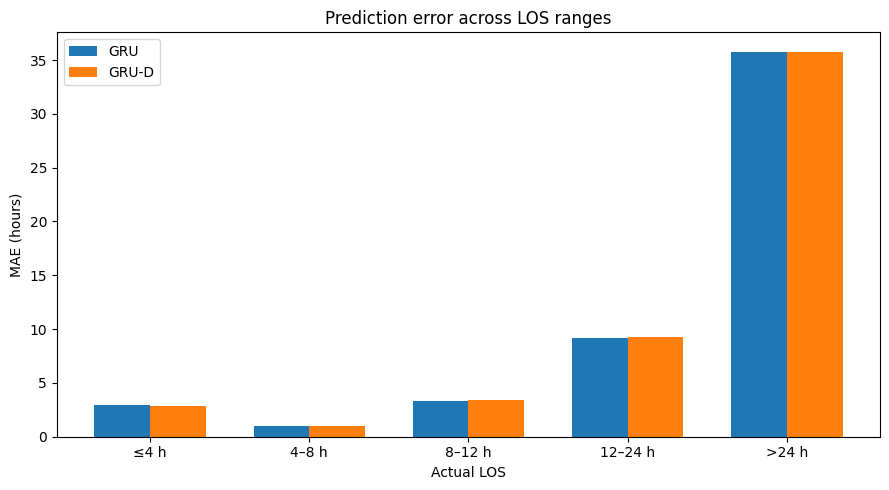


BOOTSTRAP 95% CONFIDENCE INTERVALS


,Metric,Bootstrap mean,95% CI lower,95% CI upper
0,GRU RMSE,3.8854,3.3691,4.4815
1,GRU MAE,2.3550,2.2757,2.4362
2,GRU-D RMSE,3.8849,3.3611,4.4800
3,GRU-D MAE,2.3386,2.2605,2.4193



FINAL GRU / GRU-D SUMMARY
GRU   RMSE : 3.9013 h
GRU-D RMSE : 3.9007 h
RMSE change: 0.01% improvement

GRU   MAE  : 2.3546 h
GRU-D MAE  : 2.3381 h
MAE change : 0.70% improvement

✓ GRU-D outperformed GRU on both RMSE and MAE.

Results saved to: /kaggle/working/medfusionnet_clean

GRU + GRU-D ANALYSIS COMPLETE


In [67]:
# =====================================================================
# MEDFUSIONNET — COMPLETE GRU + GRU-D BLOCK
# Train → Validate → Test → Metrics → CI → Visualizations → Explainability
# =====================================================================

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# =====================================================================
# 1. REPRODUCIBILITY
# =====================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("MEDFUSIONNET — GRU + GRU-D")
print("=" * 75)

print("Device:", DEVICE)


# =====================================================================
# 2. CHECK REQUIRED DATA
# =====================================================================

required_variables = [
    "Xt_tr", "M_tr", "D_tr", "y_tr",
    "Xt_va", "M_va", "D_va", "y_va",
    "Xt_te", "M_te", "D_te", "y_te"
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:

    raise RuntimeError(
        "Missing temporal variables:\n"
        + "\n".join(missing_variables)
        + "\n\nRun the temporal tensor-building cell first."
    )


# Convert everything to NumPy

Xt_tr = np.asarray(Xt_tr, dtype=np.float32)
M_tr  = np.asarray(M_tr, dtype=np.float32)
D_tr  = np.asarray(D_tr, dtype=np.float32)
y_tr  = np.asarray(y_tr, dtype=np.float32).reshape(-1)

Xt_va = np.asarray(Xt_va, dtype=np.float32)
M_va  = np.asarray(M_va, dtype=np.float32)
D_va  = np.asarray(D_va, dtype=np.float32)
y_va  = np.asarray(y_va, dtype=np.float32).reshape(-1)

Xt_te = np.asarray(Xt_te, dtype=np.float32)
M_te  = np.asarray(M_te, dtype=np.float32)
D_te  = np.asarray(D_te, dtype=np.float32)
y_te  = np.asarray(y_te, dtype=np.float32).reshape(-1)


print("\nDATA SHAPES")
print("-" * 75)

print("TRAIN :", Xt_tr.shape, M_tr.shape, D_tr.shape, y_tr.shape)
print("VAL   :", Xt_va.shape, M_va.shape, D_va.shape, y_va.shape)
print("TEST  :", Xt_te.shape, M_te.shape, D_te.shape, y_te.shape)


# Alignment checks

for split_name, X, M, D, y in [
    ("TRAIN", Xt_tr, M_tr, D_tr, y_tr),
    ("VAL",   Xt_va, M_va, D_va, y_va),
    ("TEST",  Xt_te, M_te, D_te, y_te)
]:

    if not (
        len(X) == len(M) == len(D) == len(y)
    ):

        raise ValueError(
            f"{split_name} tensors are not aligned."
        )


if Xt_tr.ndim != 3:

    raise ValueError(
        f"Xt_tr must be 3-D [N,T,F]. Got {Xt_tr.shape}"
    )


N_TRAIN, SEQ_LEN, N_FEATURES = Xt_tr.shape

print("\nSequence length :", SEQ_LEN)
print("Number features:", N_FEATURES)


# =====================================================================
# 3. FEATURE NAMES
# =====================================================================

if (
    "VITALS" in globals()
    and
    VITALS is not None
    and
    len(VITALS) == N_FEATURES
):

    FEATURE_NAMES = list(VITALS)

else:

    FEATURE_NAMES = [
        f"Vital_{i+1}"
        for i in range(N_FEATURES)
    ]


print("Features:", FEATURE_NAMES)


# =====================================================================
# 4. TARGET VALIDITY
# =====================================================================

for split_name, y in [
    ("TRAIN", y_tr),
    ("VAL", y_va),
    ("TEST", y_te)
]:

    bad = np.sum(
        ~np.isfinite(y)
    )

    print(
        f"{split_name} non-finite targets:",
        bad
    )

    if bad > 0:

        raise ValueError(
            f"{split_name} target contains NaN/Inf."
        )


# =====================================================================
# 5. NORMALIZATION
#
# IMPORTANT:
# Statistics are estimated using TRAINING OBSERVED VALUES ONLY.
# Missing normalized values become zero.
# M and D preserve missingness information for GRU-D.
# =====================================================================

means = np.zeros(
    N_FEATURES,
    dtype=np.float32
)

stds = np.ones(
    N_FEATURES,
    dtype=np.float32
)


for j in range(N_FEATURES):

    observed = (
        (M_tr[:, :, j] > 0)
        &
        np.isfinite(
            Xt_tr[:, :, j]
        )
    )

    values = Xt_tr[
        :,
        :,
        j
    ][observed]


    if len(values) > 0:

        means[j] = np.mean(values)

        s = np.std(values)

        stds[j] = (
            s if s > 1e-6 else 1.0
        )


def normalize_temporal(X, M):

    Xn = np.zeros_like(
        X,
        dtype=np.float32
    )

    for j in range(
        X.shape[2]
    ):

        observed = (
            (M[:, :, j] > 0)
            &
            np.isfinite(
                X[:, :, j]
            )
        )

        Xn[:, :, j][observed] = (
            X[:, :, j][observed]
            -
            means[j]
        ) / stds[j]

    return Xn


Xtr = normalize_temporal(
    Xt_tr,
    M_tr
)

Xva = normalize_temporal(
    Xt_va,
    M_va
)

Xte = normalize_temporal(
    Xt_te,
    M_te
)


# Time gaps must be finite

Dtr = np.nan_to_num(
    D_tr,
    nan=0.0,
    posinf=float(SEQ_LEN),
    neginf=0.0
)

Dva = np.nan_to_num(
    D_va,
    nan=0.0,
    posinf=float(SEQ_LEN),
    neginf=0.0
)

Dte = np.nan_to_num(
    D_te,
    nan=0.0,
    posinf=float(SEQ_LEN),
    neginf=0.0
)


print("\nNormalization complete.")

print(
    "Training X finite:",
    np.isfinite(Xtr).all()
)

print(
    "Training D finite:",
    np.isfinite(Dtr).all()
)


# =====================================================================
# 6. DATA LOADERS
# =====================================================================

BATCH_SIZE = 256


def make_loader(
    X,
    M,
    D,
    y,
    shuffle=False
):

    dataset = TensorDataset(

        torch.tensor(
            X,
            dtype=torch.float32
        ),

        torch.tensor(
            M,
            dtype=torch.float32
        ),

        torch.tensor(
            D,
            dtype=torch.float32
        ),

        torch.tensor(
            y,
            dtype=torch.float32
        )
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0
    )


train_loader = make_loader(
    Xtr,
    M_tr,
    Dtr,
    y_tr,
    shuffle=True
)

val_loader = make_loader(
    Xva,
    M_va,
    Dva,
    y_va
)

test_loader = make_loader(
    Xte,
    M_te,
    Dte,
    y_te
)


# =====================================================================
# 7. STANDARD GRU
# =====================================================================

class GRURegressor(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        dropout=0.20
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.output = nn.Linear(
            hidden_dim,
            1
        )


    def forward(
        self,
        X,
        M=None,
        D=None
    ):

        _, h = self.gru(X)

        h = h[-1]

        h = self.dropout(h)

        prediction = self.output(
            h
        ).squeeze(-1)

        return prediction


# =====================================================================
# 8. GRU-D
#
# Uses:
# X = values
# M = observation mask
# D = time since previous observation
#
# Missing values decay toward training-set mean.
# Hidden state also decays according to elapsed time.
# =====================================================================

class GRUDRegressor(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        dropout=0.20
    ):

        super().__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        # Input decay
        self.gamma_x = nn.Linear(
            input_dim,
            input_dim
        )

        # Hidden-state decay
        self.gamma_h = nn.Linear(
            input_dim,
            hidden_dim
        )

        # GRUCell receives:
        # imputed X + missingness mask
        self.gru_cell = nn.GRUCell(
            input_dim * 2,
            hidden_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.output = nn.Linear(
            hidden_dim,
            1
        )


    def forward(
        self,
        X,
        M,
        D
    ):

        batch_size = X.size(0)

        h = torch.zeros(
            batch_size,
            self.hidden_dim,
            device=X.device
        )

        # Because X has already been normalized,
        # training mean corresponds approximately to zero.
        x_mean = torch.zeros(
            self.input_dim,
            device=X.device
        )

        x_last = x_mean.unsqueeze(
            0
        ).repeat(
            batch_size,
            1
        )


        for t in range(
            X.size(1)
        ):

            x_t = X[:, t, :]
            m_t = M[:, t, :]
            d_t = D[:, t, :]


            # ---------------------------------------------
            # Input decay
            # ---------------------------------------------

            gamma_x = torch.exp(
                -torch.relu(
                    self.gamma_x(
                        d_t
                    )
                )
            )


            # ---------------------------------------------
            # Hidden decay
            # ---------------------------------------------

            gamma_h = torch.exp(
                -torch.relu(
                    self.gamma_h(
                        d_t
                    )
                )
            )


            h = (
                gamma_h * h
            )


            # ---------------------------------------------
            # Decay previous observation toward mean
            # ---------------------------------------------

            x_decay = (
                gamma_x * x_last
                +
                (1.0 - gamma_x)
                * x_mean
            )


            # Observed value if available;
            # otherwise decayed previous observation

            x_hat = (
                m_t * x_t
                +
                (1.0 - m_t)
                * x_decay
            )


            # ---------------------------------------------
            # Update last observed values
            # ---------------------------------------------

            x_last = (
                m_t * x_t
                +
                (1.0 - m_t)
                * x_last
            )


            # Include missingness mask explicitly

            gru_input = torch.cat(
                [
                    x_hat,
                    m_t
                ],
                dim=1
            )


            h = self.gru_cell(
                gru_input,
                h
            )


        h = self.dropout(h)

        prediction = self.output(
            h
        ).squeeze(-1)

        return prediction


# =====================================================================
# 9. INITIALIZE MODELS
# =====================================================================

HIDDEN_DIM = 64

gru_model = GRURegressor(
    input_dim=N_FEATURES,
    hidden_dim=HIDDEN_DIM
).to(DEVICE)


grud_model = GRUDRegressor(
    input_dim=N_FEATURES,
    hidden_dim=HIDDEN_DIM
).to(DEVICE)


print("\nGRU parameters:", sum(
    p.numel()
    for p in gru_model.parameters()
))

print("GRU-D parameters:", sum(
    p.numel()
    for p in grud_model.parameters()
))


# =====================================================================
# 10. TRAINING FUNCTION
# =====================================================================

def evaluate_loss(
    model,
    loader,
    criterion
):

    model.eval()

    losses = []

    with torch.no_grad():

        for X, M, D, y in loader:

            X = X.to(DEVICE)
            M = M.to(DEVICE)
            D = D.to(DEVICE)
            y = y.to(DEVICE)

            pred = model(
                X,
                M,
                D
            )

            if not torch.isfinite(
                pred
            ).all():

                raise RuntimeError(
                    "Model produced NaN/Inf predictions."
                )

            loss = criterion(
                pred,
                y
            )

            losses.append(
                loss.item()
                *
                len(y)
            )

    return (
        np.sum(losses)
        /
        len(loader.dataset)
    )


def train_model(
    model,
    name,
    epochs=25,
    patience=5
):

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-5
    )


    best_val = np.inf
    best_state = None
    wait = 0

    history = {
        "train": [],
        "val": []
    }


    print("\n" + "=" * 75)
    print("TRAINING", name)
    print("=" * 75)


    for epoch in range(
        1,
        epochs + 1
    ):

        model.train()

        train_loss_sum = 0.0


        for X, M, D, y in train_loader:

            X = X.to(DEVICE)
            M = M.to(DEVICE)
            D = D.to(DEVICE)
            y = y.to(DEVICE)


            optimizer.zero_grad()


            pred = model(
                X,
                M,
                D
            )


            if not torch.isfinite(
                pred
            ).all():

                raise RuntimeError(
                    f"{name} produced NaN/Inf during training."
                )


            loss = criterion(
                pred,
                y
            )


            if not torch.isfinite(
                loss
            ):

                raise RuntimeError(
                    f"{name} loss became NaN/Inf."
                )


            loss.backward()


            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )


            optimizer.step()


            train_loss_sum += (
                loss.item()
                *
                len(y)
            )


        train_loss = (
            train_loss_sum
            /
            len(train_loader.dataset)
        )


        val_loss = evaluate_loss(
            model,
            val_loader,
            criterion
        )


        history["train"].append(
            train_loss
        )

        history["val"].append(
            val_loss
        )


        print(
            f"{name:6s} | "
            f"Epoch {epoch:02d} | "
            f"Train RMSE={np.sqrt(train_loss):.4f} | "
            f"Val RMSE={np.sqrt(val_loss):.4f}"
        )


        # Early stopping

        if val_loss < best_val:

            best_val = val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            wait = 0

        else:

            wait += 1


        if wait >= patience:

            print(
                f"Early stopping {name} "
                f"at epoch {epoch}."
            )

            break


    if best_state is None:

        raise RuntimeError(
            f"No valid checkpoint produced for {name}."
        )


    model.load_state_dict(
        best_state
    )


    return model, history


# =====================================================================
# 11. TRAIN GRU
# =====================================================================

gru_model, gru_history = train_model(
    gru_model,
    "GRU"
)


# =====================================================================
# 12. TRAIN GRU-D
# =====================================================================

grud_model, grud_history = train_model(
    grud_model,
    "GRU-D"
)


# =====================================================================
# 13. PREDICTION FUNCTION
# =====================================================================

def predict_model(
    model,
    loader
):

    model.eval()

    predictions = []
    targets = []


    with torch.no_grad():

        for X, M, D, y in loader:

            X = X.to(DEVICE)
            M = M.to(DEVICE)
            D = D.to(DEVICE)


            pred = model(
                X,
                M,
                D
            )


            predictions.append(
                pred.cpu().numpy()
            )

            targets.append(
                y.numpy()
            )


    predictions = np.concatenate(
        predictions
    )

    targets = np.concatenate(
        targets
    )


    if not np.all(
        np.isfinite(
            predictions
        )
    ):

        raise RuntimeError(
            "Predictions contain NaN/Inf. "
            "Results will NOT be calculated."
        )


    return predictions, targets


# =====================================================================
# 14. TEST PREDICTIONS
# =====================================================================

pred_gru_test, y_test_check = predict_model(
    gru_model,
    test_loader
)


pred_grud_test, y_test_check2 = predict_model(
    grud_model,
    test_loader
)


if not np.allclose(
    y_test_check,
    y_te
):

    raise RuntimeError(
        "Test target alignment error."
    )


if not np.allclose(
    y_test_check2,
    y_te
):

    raise RuntimeError(
        "GRU-D target alignment error."
    )


print("\nPredictions generated.")

print(
    "GRU:",
    pred_gru_test.shape
)

print(
    "GRU-D:",
    pred_grud_test.shape
)


# =====================================================================
# 15. PERFORMANCE METRICS
# =====================================================================

def regression_metrics(
    name,
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    medae = np.median(
        np.abs(
            y_true - y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )


    return {
        "Model": name,
        "RMSE (h)": rmse,
        "MAE (h)": mae,
        "Median AE (h)": medae,
        "R²": r2
    }


results_df = pd.DataFrame([
    regression_metrics(
        "GRU",
        y_te,
        pred_gru_test
    ),

    regression_metrics(
        "GRU-D",
        y_te,
        pred_grud_test
    )
])


print("\n" + "=" * 75)
print("TEST RESULTS")
print("=" * 75)

display(
    results_df.round(4)
)


# =====================================================================
# 16. TRAINING / VALIDATION LOSS CURVES
# =====================================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    np.sqrt(
        gru_history["train"]
    ),
    label="GRU train"
)

ax.plot(
    np.sqrt(
        gru_history["val"]
    ),
    label="GRU validation"
)

ax.plot(
    np.sqrt(
        grud_history["train"]
    ),
    label="GRU-D train"
)

ax.plot(
    np.sqrt(
        grud_history["val"]
    ),
    label="GRU-D validation"
)

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "RMSE (hours)"
)

ax.set_title(
    "GRU and GRU-D training convergence"
)

ax.legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 17. GRU VS GRU-D METRIC BAR CHART
# =====================================================================

x = np.arange(2)

width = 0.35


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    x - width / 2,
    results_df["RMSE (h)"],
    width,
    label="RMSE"
)


ax.bar(
    x + width / 2,
    results_df["MAE (h)"],
    width,
    label="MAE"
)


ax.set_xticks(x)

ax.set_xticklabels(
    results_df["Model"]
)

ax.set_ylabel(
    "Error (hours)"
)

ax.set_title(
    "GRU vs GRU-D LOS prediction performance"
)

ax.legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 18. ACTUAL VS PREDICTED — GRU
# =====================================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.scatter(
    y_te,
    pred_gru_test,
    alpha=0.25
)


low = min(
    y_te.min(),
    pred_gru_test.min()
)

high = max(
    y_te.max(),
    pred_gru_test.max()
)


ax.plot(
    [low, high],
    [low, high],
    linestyle="--"
)


ax.set_xlabel(
    "Actual LOS (hours)"
)

ax.set_ylabel(
    "Predicted LOS (hours)"
)

ax.set_title(
    "GRU: actual vs predicted LOS"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 19. ACTUAL VS PREDICTED — GRU-D
# =====================================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.scatter(
    y_te,
    pred_grud_test,
    alpha=0.25
)


low = min(
    y_te.min(),
    pred_grud_test.min()
)

high = max(
    y_te.max(),
    pred_grud_test.max()
)


ax.plot(
    [low, high],
    [low, high],
    linestyle="--"
)


ax.set_xlabel(
    "Actual LOS (hours)"
)

ax.set_ylabel(
    "Predicted LOS (hours)"
)

ax.set_title(
    "GRU-D: actual vs predicted LOS"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 20. RESIDUAL ANALYSIS
# =====================================================================

residual_gru = (
    y_te - pred_gru_test
)

residual_grud = (
    y_te - pred_grud_test
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.scatter(
    pred_gru_test,
    residual_gru,
    alpha=0.25
)

ax.axhline(
    0,
    linestyle="--"
)

ax.set_xlabel(
    "Predicted LOS (hours)"
)

ax.set_ylabel(
    "Residual (actual − predicted)"
)

ax.set_title(
    "GRU residual analysis"
)

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.scatter(
    pred_grud_test,
    residual_grud,
    alpha=0.25
)

ax.axhline(
    0,
    linestyle="--"
)

ax.set_xlabel(
    "Predicted LOS (hours)"
)

ax.set_ylabel(
    "Residual (actual − predicted)"
)

ax.set_title(
    "GRU-D residual analysis"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 21. ABSOLUTE ERROR DISTRIBUTION
# =====================================================================

error_gru = np.abs(
    y_te - pred_gru_test
)

error_grud = np.abs(
    y_te - pred_grud_test
)


fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    error_gru,
    bins=50,
    alpha=0.6,
    density=True,
    label="GRU"
)

ax.hist(
    error_grud,
    bins=50,
    alpha=0.6,
    density=True,
    label="GRU-D"
)

ax.set_xlabel(
    "Absolute prediction error (hours)"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "LOS prediction error distribution"
)

ax.legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 22. CUMULATIVE ERROR CURVE
# =====================================================================

max_threshold = min(
    24,
    max(
        np.percentile(
            error_gru,
            95
        ),
        np.percentile(
            error_grud,
            95
        )
    )
)


thresholds = np.linspace(
    0,
    max_threshold,
    50
)


gru_within = [
    100 * np.mean(
        error_gru <= t
    )
    for t in thresholds
]


grud_within = [
    100 * np.mean(
        error_grud <= t
    )
    for t in thresholds
]


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    thresholds,
    gru_within,
    label="GRU"
)

ax.plot(
    thresholds,
    grud_within,
    label="GRU-D"
)

ax.set_xlabel(
    "Absolute error threshold (hours)"
)

ax.set_ylabel(
    "Predictions within threshold (%)"
)

ax.set_title(
    "Cumulative LOS prediction accuracy"
)

ax.legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 23. MISSINGNESS EXPLAINABILITY
# =====================================================================

observed_fraction = (
    M_tr.mean(
        axis=(0, 1)
    )
)

missing_fraction = (
    1.0 - observed_fraction
)


missing_df = pd.DataFrame({
    "Vital": FEATURE_NAMES,
    "Observed (%)":
        observed_fraction * 100,
    "Missing (%)":
        missing_fraction * 100
})


print("\nMISSINGNESS")

display(
    missing_df.round(2)
)


plot_missing = (
    missing_df
    .sort_values(
        "Missing (%)"
    )
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.barh(
    plot_missing["Vital"],
    plot_missing["Missing (%)"]
)

ax.set_xlabel(
    "Missing measurements (%)"
)

ax.set_title(
    "Vital-sign missingness during first 60 minutes"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 24. TEMPORAL OBSERVATION HEATMAP
# =====================================================================

observation_rate = (
    M_tr.mean(
        axis=0
    )
)


fig, ax = plt.subplots(
    figsize=(12, 5)
)

im = ax.imshow(
    observation_rate.T,
    aspect="auto",
    origin="lower",
    vmin=0,
    vmax=1
)

ax.set_xlabel(
    "Time step (minute)"
)

ax.set_ylabel(
    "Vital sign"
)

ax.set_yticks(
    np.arange(
        N_FEATURES
    )
)

ax.set_yticklabels(
    FEATURE_NAMES
)

ax.set_title(
    "Temporal availability of vital-sign measurements"
)

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Observed fraction"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 25. GRU-D TIME-GAP EXPLAINABILITY
# =====================================================================

gap_rows = []


for j, feature in enumerate(
    FEATURE_NAMES
):

    gaps = D_tr[
        :,
        :,
        j
    ].reshape(-1)

    gaps = gaps[
        np.isfinite(gaps)
    ]


    gap_rows.append({
        "Vital": feature,

        "Mean gap":
            np.mean(gaps),

        "Median gap":
            np.median(gaps),

        "95th percentile":
            np.percentile(
                gaps,
                95
            )
    })


gap_df = pd.DataFrame(
    gap_rows
)


print("\nTIME-GAP STATISTICS")

display(
    gap_df.round(3)
)


plot_gap = (
    gap_df
    .sort_values(
        "Mean gap"
    )
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.barh(
    plot_gap["Vital"],
    plot_gap["Mean gap"]
)

ax.set_xlabel(
    "Mean time since last observation (minutes)"
)

ax.set_title(
    "Observation-gap characteristics used by GRU-D"
)

plt.tight_layout()
plt.show()


# =====================================================================
# 26. DOES GRU-D HELP MORE WITH MISSING DATA?
# =====================================================================

test_missingness = (
    1.0
    -
    M_te.mean(
        axis=(1, 2)
    )
)


grud_improvement = (
    error_gru
    -
    error_grud
)


fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    test_missingness * 100,
    grud_improvement,
    alpha=0.25
)

ax.axhline(
    0,
    linestyle="--"
)

ax.set_xlabel(
    "Missing measurements per encounter (%)"
)

ax.set_ylabel(
    "GRU error − GRU-D error (hours)"
)

ax.set_title(
    "GRU-D relative performance versus missingness"
)

plt.tight_layout()
plt.show()


if np.std(test_missingness) > 0:

    missing_corr = np.corrcoef(
        test_missingness,
        grud_improvement
    )[0, 1]

else:

    missing_corr = np.nan


print(
    "Missingness / GRU-D improvement correlation:",
    round(
        float(missing_corr),
        4
    )
)


# =====================================================================
# 27. PERFORMANCE BY MISSINGNESS QUARTILE
# =====================================================================

missing_analysis = pd.DataFrame({
    "Missingness":
        test_missingness,

    "GRU_error":
        error_gru,

    "GRUD_error":
        error_grud
})


try:

    missing_analysis[
        "Group"
    ] = pd.qcut(
        missing_analysis[
            "Missingness"
        ],
        q=4,
        labels=[
            "Q1 lowest",
            "Q2",
            "Q3",
            "Q4 highest"
        ],
        duplicates="drop"
    )


    quartile_df = (
        missing_analysis
        .groupby(
            "Group",
            observed=True
        )
        .agg(
            GRU_MAE=(
                "GRU_error",
                "mean"
            ),

            GRUD_MAE=(
                "GRUD_error",
                "mean"
            ),

            N=(
                "Missingness",
                "size"
            )
        )
        .reset_index()
    )


    print(
        "\nPERFORMANCE BY MISSINGNESS"
    )

    display(
        quartile_df.round(4)
    )


    x = np.arange(
        len(
            quartile_df
        )
    )

    width = 0.35


    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.bar(
        x - width / 2,
        quartile_df[
            "GRU_MAE"
        ],
        width,
        label="GRU"
    )

    ax.bar(
        x + width / 2,
        quartile_df[
            "GRUD_MAE"
        ],
        width,
        label="GRU-D"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        quartile_df[
            "Group"
        ]
    )

    ax.set_ylabel(
        "MAE (hours)"
    )

    ax.set_xlabel(
        "Missingness quartile"
    )

    ax.set_title(
        "GRU vs GRU-D across missingness levels"
    )

    ax.legend()

    plt.tight_layout()
    plt.show()


except Exception as e:

    print(
        "Missingness quartile plot skipped:",
        e
    )


# =====================================================================
# 28. PERFORMANCE BY LOS RANGE
# =====================================================================

los_analysis = pd.DataFrame({
    "LOS": y_te,
    "GRU_error": error_gru,
    "GRUD_error": error_grud
})


los_analysis[
    "LOS group"
] = pd.cut(
    los_analysis[
        "LOS"
    ],
    bins=[
        -np.inf,
        4,
        8,
        12,
        24,
        np.inf
    ],
    labels=[
        "≤4 h",
        "4–8 h",
        "8–12 h",
        "12–24 h",
        ">24 h"
    ]
)


los_group_df = (
    los_analysis
    .groupby(
        "LOS group",
        observed=True
    )
    .agg(
        GRU_MAE=(
            "GRU_error",
            "mean"
        ),

        GRUD_MAE=(
            "GRUD_error",
            "mean"
        ),

        N=(
            "LOS",
            "size"
        )
    )
    .reset_index()
)


print("\nPERFORMANCE BY LOS RANGE")

display(
    los_group_df.round(4)
)


x = np.arange(
    len(
        los_group_df
    )
)

width = 0.35


fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    x - width / 2,
    los_group_df[
        "GRU_MAE"
    ],
    width,
    label="GRU"
)

ax.bar(
    x + width / 2,
    los_group_df[
        "GRUD_MAE"
    ],
    width,
    label="GRU-D"
)

ax.set_xticks(x)

ax.set_xticklabels(
    los_group_df[
        "LOS group"
    ]
)

ax.set_xlabel(
    "Actual LOS"
)

ax.set_ylabel(
    "MAE (hours)"
)

ax.set_title(
    "Prediction error across LOS ranges"
)

ax.legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 29. BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

N_BOOT = 1000

rng = np.random.default_rng(
    SEED
)

boot = []

n_test = len(
    y_te
)


for _ in range(
    N_BOOT
):

    idx = rng.integers(
        0,
        n_test,
        n_test
    )


    yt = y_te[idx]

    pg = pred_gru_test[idx]

    pd_ = pred_grud_test[idx]


    boot.append([

        np.sqrt(
            mean_squared_error(
                yt,
                pg
            )
        ),

        mean_absolute_error(
            yt,
            pg
        ),

        np.sqrt(
            mean_squared_error(
                yt,
                pd_
            )
        ),

        mean_absolute_error(
            yt,
            pd_
        )
    ])


boot = np.asarray(
    boot
)


metric_names = [
    "GRU RMSE",
    "GRU MAE",
    "GRU-D RMSE",
    "GRU-D MAE"
]


ci_rows = []


for j, name in enumerate(
    metric_names
):

    ci_rows.append({
        "Metric": name,

        "Bootstrap mean":
            boot[:, j].mean(),

        "95% CI lower":
            np.percentile(
                boot[:, j],
                2.5
            ),

        "95% CI upper":
            np.percentile(
                boot[:, j],
                97.5
            )
    })


ci_df = pd.DataFrame(
    ci_rows
)


print("\n" + "=" * 75)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 75)

display(
    ci_df.round(4)
)


# =====================================================================
# 30. MODEL IMPROVEMENT SUMMARY
# =====================================================================

gru_rmse = results_df.loc[
    results_df["Model"] == "GRU",
    "RMSE (h)"
].iloc[0]

grud_rmse = results_df.loc[
    results_df["Model"] == "GRU-D",
    "RMSE (h)"
].iloc[0]


gru_mae = results_df.loc[
    results_df["Model"] == "GRU",
    "MAE (h)"
].iloc[0]

grud_mae = results_df.loc[
    results_df["Model"] == "GRU-D",
    "MAE (h)"
].iloc[0]


rmse_improvement = (
    100
    *
    (gru_rmse - grud_rmse)
    /
    gru_rmse
)


mae_improvement = (
    100
    *
    (gru_mae - grud_mae)
    /
    gru_mae
)


print("\n" + "=" * 75)
print("FINAL GRU / GRU-D SUMMARY")
print("=" * 75)

print(
    f"GRU   RMSE : {gru_rmse:.4f} h"
)

print(
    f"GRU-D RMSE : {grud_rmse:.4f} h"
)

print(
    f"RMSE change: {rmse_improvement:.2f}% improvement"
)


print()

print(
    f"GRU   MAE  : {gru_mae:.4f} h"
)

print(
    f"GRU-D MAE  : {grud_mae:.4f} h"
)

print(
    f"MAE change : {mae_improvement:.2f}% improvement"
)


if (
    grud_rmse < gru_rmse
    and
    grud_mae < gru_mae
):

    print(
        "\n✓ GRU-D outperformed GRU on both "
        "RMSE and MAE."
    )

else:

    print(
        "\n⚠ GRU-D did NOT outperform GRU "
        "on both primary metrics."
    )

    print(
        "Do not claim GRU-D superiority "
        "in the paper unless supported by the results."
    )


# =====================================================================
# 31. SAVE RESULTS
# =====================================================================

try:

    from pathlib import Path

    OUTPUT_DIR = Path(
        "/kaggle/working/medfusionnet_clean"
    )

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    results_df.to_csv(
        OUTPUT_DIR /
        "gru_grud_test_results.csv",
        index=False
    )


    ci_df.to_csv(
        OUTPUT_DIR /
        "gru_grud_bootstrap_ci.csv",
        index=False
    )


    missing_df.to_csv(
        OUTPUT_DIR /
        "temporal_missingness.csv",
        index=False
    )


    print(
        "\nResults saved to:",
        OUTPUT_DIR
    )


except Exception as e:

    print(
        "\nSaving skipped:",
        e
    )


print("\n" + "=" * 75)
print("GRU + GRU-D ANALYSIS COMPLETE")
print("=" * 75)